[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/owlmt/QML/blob/main/27_QML_Privacy_Data_Leakage/VQC_TrustworthyQML_Catak2025.ipynb)

# Variational quantum classifier for trustworthy QML: Catak, Seo and Cali (2025) step by step

**Paper.** Ferhat Ozgur Catak, Jungwon Seo and Umit Cali, *Trustworthy Quantum Machine Learning: A Roadmap for Reliability, Robustness, and Security in the NISQ Era*, 2025, arXiv:2511.02602 (https://arxiv.org/abs/2511.02602). The authors' own code is at https://github.com/ocatak/trustworthy-quantum-machine-learning (three notebooks: `Uncertainty-QML`, `Adversarial-QML`, `FL-QML`). This notebook re-implements Section V ("Experimental Demonstrations") of the paper and uses that repository only to resolve details the paper leaves open; every such place is marked `# CHOICE:` and listed in the table below.

**What the notebook does.** Sections II to IV of the paper are a roadmap (theory); the only experiments are three small demonstrations built around one tiny classifier, a 2-qubit variational quantum circuit trained with SPSA:

1. **V-A Uncertainty.** Do shot-based uncertainty scores (predictive entropy, variation ratio, ...) tell correct predictions from wrong ones? (two-moons data)
2. **V-B Adversarial robustness.** How much do FGSM, PGD and a "quantum-state" noise attack hurt the classifier, and does adversarial training help? (two-moons data)
3. **V-C Federated learning and privacy.** How much accuracy does federated averaging (FedAvg) cost, and how much more does Gaussian differential-privacy noise cost? A membership-inference attack measures privacy leakage. (Breast Cancer Wisconsin data, see the table below for why)

Next to the quantum model every experiment also runs **classical baselines on exactly the same inputs** (logistic regression, RBF-SVM, random forest, small MLP, and a federated logistic regression), and the last section prints the paper's numbers next to ours with a verdict per claim.

**How to run.** Open in Google Colab, choose a *CPU* runtime, then *Runtime -> Run all*. `FAST_MODE = True` (3 federated runs, 3 seeds, 5 repeats of the random attack) finishes in about 4 minutes; `FAST_MODE = False` (the shipped, executed version) uses the paper's budgets (10 independent runs, 20 repeats of the random attack) and takes about 6 to 11 minutes on a CPU runtime, depending on how busy the machine is. The first cell installs pinned libraries (Qiskit 2.5.2, Qiskit Aer 0.17.2); on Colab you may be asked to restart the session once, then run all again.

**What you get at the end.** Re-drawn versions of the paper's tables and figures (Tables III, IV, VI, VIII, IX, X; Figures 4 to 13), real-data plots, the executed 2-qubit circuit, and a verdict table: *reproduced*, *not reached*, *exceeded* or *cannot be checked*. No Hugging Face token is needed: two-moons is generated with scikit-learn and Breast Cancer Wisconsin ships inside scikit-learn.

## The paper in one page

**Problem.** Quantum machine learning (QML) on NISQ hardware has trust problems that classical ML mostly handles with mature tools: predictions are random (Born rule and finite shots), inputs can be adversarially perturbed, and distributed/delegated training can leak private data. The paper proposes a roadmap with three pillars: (i) uncertainty quantification, (ii) adversarial robustness, (iii) privacy preservation.

**Decision.** Binary classification with a variational quantum classifier (VQC). The label is the sign of the Pauli-Z expectation value of one qubit; the "trust" tools are layered on top (entropy of the measurement outcomes, attacks on the inputs, differential privacy on federated updates).

**Method (Section V).**
- *Model:* 2 qubits. Angle encoding by RY rotations of the two features, a 4-parameter ansatz of RY rotations and one CNOT, decision `sign(<Z>)`.
- *Training:* squared-hinge loss, SPSA optimiser, 50 iterations; 200 shots for the uncertainty analysis (Table III: depth 4, 4 trainable parameters, 900 train / 600 test).
- *V-A:* per-sample predictive entropy, variation ratio, standard deviation and max-confidence from the 200 shots; compare correct vs wrong predictions (Table IV, Figure 4); shot-count study (Table VI).
- *V-B:* FGSM, PGD (10 steps, step eps/10) and a random "quantum-state" perturbation of the encoding angles for eps in {0, 0.05, 0.1, 0.15, 0.2, 0.3, 0.5}; adversarial training with FGSM at eps = 0.15; Lipschitz estimate and transferability (Tables VIII, IX).
- *V-C:* 4 clients, FedAvg, Gaussian noise on the clipped client updates for several privacy budgets, membership-inference attack, 10 independent runs (Tables X, XI, XII; Figures 12 to 15).

**Headline claims.** Test accuracy 87.5% (525/600); mean entropy 0.471 for correct vs 0.900 for wrong predictions (Cohen's d = 1.434); clean accuracy 88% on 100 test points falling to about 71% under PGD at eps = 0.5; average accuracy drop 6.9% for FGSM and for PGD and -0.4% for the quantum-state attack; federated accuracy 84.2% (centralised), 80.7% (FedAvg, IID) and 73.7% with differential privacy at total eps = 20.

**Data.** Two-moons (1500 points, 60/40 split, standardised) for V-A and V-B. The paper does not name the data of V-C.

## What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Two-moons generator | 1500 samples; noise level not stated | `make_moons(n_samples=1500, noise=0.1, random_state=42)`; noise 0.1 and seed 42 read from the authors' repository (CHOICE) |
| Split / scaling | 60/40, standardised | `train_test_split(test_size=0.4, random_state=42)`, `StandardScaler` fitted on the training part only |
| Circuit | RY encoding, RY + CNOT ansatz, 4 parameters, depth 4 | RY(x1) q0, RY(x2) q1, RY(t1) q0, RY(t2) q1, CNOT(0,1), RY(t3) q0, RY(t4) q1 (order from the authors' repository, CHOICE) |
| Measured observable | "Pauli-Z on qubit 0" | Z on Qiskit qubit 1, i.e. the authors' Qiskit operator label `"ZI"` (Qiskit labels are little-endian, so the left-most letter is qubit 1). The paper's text says "qubit 0", the code measures the other qubit. `OBS_QUBIT = 1` is a CHOICE; Section 6 trains both and compares |
| Optimiser | SPSA, squared hinge, 50 iterations | SPSA with constant gain a = 0.16 and perturbation c = 0.1, initial angles 0.1 * N(0,1), all from the authors' code (CHOICE) |
| Shots | 200 | 200 shots per sample on the Qiskit Aer sampler (the real circuit); the shot-count sweeps use a binomial draw from the exact probability, checked against Aer below |
| Entropy | H = -sum p log p | base-2 logarithm (the paper's values reach 0.9 with a maximum of 1, so bits); CHOICE |
| V-B subset | 100 test samples, clean accuracy 88% | first 100 test samples (as in the authors' code); we also report all 600 |
| V-B gradient | "x + eps * sign(grad)" | forward finite difference of the squared-hinge loss with step 0.01 (authors' code) |
| V-B attacks | FGSM, PGD, C&W-L2, quantum-state | FGSM, PGD, quantum-state (the paper lists C&W-L2 but reports no numbers for it) |
| Adversarial training | FGSM at eps = 0.15 | 30 SPSA iterations (iteration count from the authors' code, CHOICE) |
| V-C dataset | not stated; Table X says "600-sample test set" | **Breast Cancer Wisconsin reduced to 2 PCA components** (the authors' FL code). Evidence: every accuracy of Table X is a multiple of 1/171 (84.21% = 144/171, 80.70% = 138/171, 73.68% = 126/171, ...), and 171 is 30% of the 569 Breast Cancer samples; two-moons has 600 test samples. A two-moons variant is run as well |
| V-C clients | 4 | 4 by default (the paper); the authors' code uses 5, run as a variant |
| V-C PCA | not stated | the authors fit PCA on all 569 samples (test-set leakage). Primary run here: the authors' protocol, to match the paper; second run: PCA and scaler fitted on the training split only |
| V-C DP | Gaussian noise, eps = 0.5/1/10 | clip update to norm 1, sigma = sqrt(2 ln(1.25/delta)) / eps with delta = 1e-5 (authors' code); total eps = per-round eps * 20 rounds (simple composition; the paper says "strong composition" but its totals are exactly eps * 20) |
| V-C membership inference | shadow models, 1000 members | the authors' code: logistic regression on the per-sample loss of 100 train and 100 test points |
| Repeats | 10 runs | 10 runs when `FAST_MODE = False`, 3 when `True`; the authors' code is one run with seed 42, which we also print |

## 0. Install pinned libraries

Colab already ships numpy, pandas, scikit-learn, scipy and matplotlib. We only need Qiskit and the Aer simulator. The cell does nothing if the right packages are already importable (for example when you run it locally).

In [1]:
import sys, subprocess, importlib

IN_COLAB = "google.colab" in sys.modules

def _have(mod):
    try:
        importlib.import_module(mod)
        return True
    except Exception:
        return False

if IN_COLAB or not (_have("qiskit") and _have("qiskit_aer") and _have("pylatexenc")):
    subprocess.run([sys.executable, "-m", "pip", "-q", "install",
                    "qiskit==2.5.2", "qiskit-aer==0.17.2", "pylatexenc"], check=True)
    print("Installed. If Colab asks for a restart, restart and run all again.")
else:
    print("Qiskit and Aer already available, nothing to install.")

Qiskit and Aer already available, nothing to install.


## 1. Configuration

Every tunable constant lives in this one cell. `FAST_MODE = True` keeps the number of repeated runs small; the quantum model itself, the data and all training budgets are the paper's in both modes.

In [2]:
import numpy as np

# ------------------------------------------------------------------ general
SEED = 42
FAST_MODE = False           # True: few repeats (about 5 min). False: paper budgets (10 runs).
DATA_DIR = "qml_data"       # nothing is downloaded here: make_moons is generated, Breast Cancer ships with scikit-learn
IBM_TOKEN = ""              # unused: this paper needs no hardware, everything is simulated

# ------------------------------------------------------------------ data (paper V-A, V-B)
N_SAMPLES = 1500
NOISE = 0.1                 # CHOICE: not in the paper; value used in the authors' repository
TEST_SIZE = 0.4             # 60/40 split, 900 train / 600 test

# ------------------------------------------------------------------ circuit and training (paper V-A)
N_QUBITS = 2
OBS_QUBIT = 1               # CHOICE: authors' Qiskit operator "ZI" = Z on qubit 1 (paper text: "qubit 0")
SPSA_ITERS = 50
SPSA_A = 0.16               # CHOICE: constant SPSA step, from the authors' code
SPSA_C = 0.1                # CHOICE: constant SPSA perturbation, from the authors' code
INIT_SCALE = 0.1            # initial angles ~ 0.1 * N(0, 1)
SHOTS = 200

# ------------------------------------------------------------------ V-A uncertainty
SHOT_GRID = np.linspace(50, 1000, 250).astype(int)   # Table VI: shots from 50 to 1000 (authors' code)
SHOT_PANELS = [10, 50, 100, 200, 500, 1000]          # Figure 5
ENTROPY_THRESHOLD = 0.7                               # selective-prediction threshold in the paper

# ------------------------------------------------------------------ V-B adversarial robustness
EPS_PAPER = [0.0, 0.05, 0.1, 0.15, 0.2, 0.3, 0.5]    # budgets of Table VIII
EPS_DENSE = np.linspace(0.0, 0.5, 50).round(3)       # dense grid of the authors' code (contains 0.204)
EPS_REP = 0.204                                       # Figure 8
N_ATTACK_SUBSET = 100                                 # first 100 test samples, as in the paper
PGD_STEPS = 10
FD_STEP = 0.01                                        # CHOICE: finite-difference step of the authors' code
ADV_TRAIN_EPS = 0.15
ADV_TRAIN_ITERS = 30                                  # CHOICE: from the authors' code

# ------------------------------------------------------------------ V-C federated learning and privacy
N_CLIENTS = 4               # the paper; the authors' code uses 5 (run as a variant)
FL_ROUNDS = 20
CENTRAL_ITERS = 30
FL_LR = 0.16
DP_DELTA = 1e-5
DP_CLIP = 1.0
DP_EPS_ROUND = [10.0, 5.0, 2.0, 1.0, 0.5, 0.1]       # per-round budgets (total = x 20 rounds)
MIA_N = 100                 # members / non-members used by the membership-inference attack

# ------------------------------------------------------------------ budgets that depend on the mode
N_SEEDS = 3 if FAST_MODE else 10      # independent training seeds for V-A / V-B robustness checks
Q_REPEATS = 5 if FAST_MODE else 20    # repeats of the random quantum-state attack
FL_RUNS = 3 if FAST_MODE else 10      # independent federated runs per configuration (paper: 10)
print(f"FAST_MODE={FAST_MODE}: N_SEEDS={N_SEEDS}, Q_REPEATS={Q_REPEATS}, FL_RUNS={FL_RUNS}")

FAST_MODE=False: N_SEEDS=10, Q_REPEATS=20, FL_RUNS=10


## 2. Imports and seeds

Everything random in this notebook is driven by `SEED` through explicit `numpy` random generators (no hidden global state), by scikit-learn's `random_state=SEED`, and by the `seed=` argument of the Qiskit Aer sampler. TensorFlow and PyTorch are not used.

In [3]:
import time, platform, warnings
warnings.filterwarnings("ignore")
T_START = time.time()

import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from scipy import stats

import sklearn
from sklearn.datasets import make_moons, load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier

import qiskit, qiskit_aer
from qiskit import QuantumCircuit, ClassicalRegister
from qiskit.circuit import ParameterVector
from qiskit.quantum_info import Statevector
from qiskit_aer.primitives import SamplerV2 as AerSamplerV2

rng = np.random.default_rng(SEED)
plt.rcParams.update({"figure.dpi": 90, "savefig.dpi": 90, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
print("python", platform.python_version(), "| numpy", np.__version__, "| pandas", pd.__version__,
      "| sklearn", sklearn.__version__, "| matplotlib", matplotlib.__version__)
print("qiskit", qiskit.__version__, "| qiskit-aer", qiskit_aer.__version__)

python 3.12.10 | numpy 2.5.4 | pandas 3.0.6 | sklearn 1.9.1 | matplotlib 3.11.2
qiskit 2.5.2 | qiskit-aer 0.17.2


## 3. Data

**Two-moons (V-A and V-B).** This is the paper's own synthetic benchmark, generated with the paper's recipe (1500 points, 60/40 split, standardised), not a substitute. Labels are mapped to {-1, +1}. The scaler is fitted on the training split only.

**Breast Cancer Wisconsin (V-C).** A real clinical dataset (569 tumours, 30 features, malignant/benign) that ships with scikit-learn. The paper never names the V-C data, but its Table X numbers are all multiples of 1/171, which is exactly the 30% test split of this dataset, and the authors' released FL code uses it (see the table above). It is reduced to 2 features by PCA because the circuit has 2 qubits. The authors fit the PCA on all 569 points before splitting; we keep that as "authors' protocol" (to match the paper) and also run a leakage-free version where PCA and scaler see the training split only.

In [4]:
# ---------------------------------------------------------------- two-moons: the paper's recipe
X_moons_raw, y01_moons = make_moons(n_samples=N_SAMPLES, noise=NOISE, random_state=SEED)
y_moons = 2 * y01_moons - 1                                  # labels in {-1, +1}
X_tr_raw, X_te_raw, y_tr, y_te = train_test_split(X_moons_raw, y_moons, test_size=TEST_SIZE, random_state=SEED)
scaler_moons = StandardScaler().fit(X_tr_raw)                # fitted on the training split only
X_tr = scaler_moons.transform(X_tr_raw)
X_te = scaler_moons.transform(X_te_raw)
X_sub, y_sub = X_te[:N_ATTACK_SUBSET], y_te[:N_ATTACK_SUBSET]  # the 100-sample subset of V-B
print("two-moons: train", X_tr.shape, "test", X_te.shape, "| attack subset", X_sub.shape)

# ---------------------------------------------------------------- Breast Cancer Wisconsin for V-C
bc = load_breast_cancer()
X_bc_full, y_bc_full = bc.data, 2 * bc.target - 1            # malignant = -1, benign = +1 (as in the authors' code)

def prepare_breast_cancer(leaky):
    # leaky=True : authors' protocol, PCA fitted on all 569 samples, then split, then scaler on train
    # leaky=False: split first, standardise + PCA + scaler fitted on the training split only
    if leaky:
        Xr = PCA(n_components=2, random_state=SEED).fit_transform(X_bc_full)
        Xtr, Xte, ytr, yte = train_test_split(Xr, y_bc_full, test_size=0.3, random_state=SEED, stratify=y_bc_full)
        sc = StandardScaler().fit(Xtr)
        return sc.transform(Xtr), sc.transform(Xte), ytr, yte
    Xtr, Xte, ytr, yte = train_test_split(X_bc_full, y_bc_full, test_size=0.3, random_state=SEED, stratify=y_bc_full)
    s0 = StandardScaler().fit(Xtr)
    p = PCA(n_components=2, random_state=SEED).fit(s0.transform(Xtr))
    Ztr, Zte = p.transform(s0.transform(Xtr)), p.transform(s0.transform(Xte))
    s1 = StandardScaler().fit(Ztr)
    return s1.transform(Ztr), s1.transform(Zte), ytr, yte

BC_AUTH = prepare_breast_cancer(leaky=True)      # (Xtr, Xte, ytr, yte), authors' protocol
BC_CLEAN = prepare_breast_cancer(leaky=False)    # leakage-free
print("breast cancer (authors' protocol): train", BC_AUTH[0].shape, "test", BC_AUTH[1].shape)
print("breast cancer (leakage-free)     : train", BC_CLEAN[0].shape, "test", BC_CLEAN[1].shape)

two-moons: train (900, 2) test (600, 2) | attack subset (100, 2)
breast cancer (authors' protocol): train (398, 2) test (171, 2)
breast cancer (leakage-free)     : train (398, 2) test (171, 2)


## Dataset Exploration and Visualisation

For both datasets we print the shape, the feature names and the original labels with class counts, plot the real class distribution, and draw 2-D scatter plots in which **every point is a real observation coloured by its ground-truth label**. The first scatter shows PCA coordinates (PCA fitted on the training split only), the second shows the two numbers that are actually fed to the circuit as RY rotation angles in radians. This model uses angle encoding of standardised features directly, so the circuit angles are the standardised coordinates (there is no extra scaling to [0, pi] in this paper).

TWO-MOONS (paper's synthetic benchmark, generated with make_moons)
full data  : (1500, 2) | feature names: ['x1', 'x2']
original make_moons labels: {0: 750, 1: 750} -> mapped to {-1, +1} for the hinge loss
train (900): {-1: 439, 1: 461} | test (600): {-1: 311, 1: 289}

BREAST CANCER WISCONSIN (real clinical data, used for V-C)
full data  : (569, 30)
feature names (30): ['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension']
original labels: {'malignant': 212, 'benign': 357} (

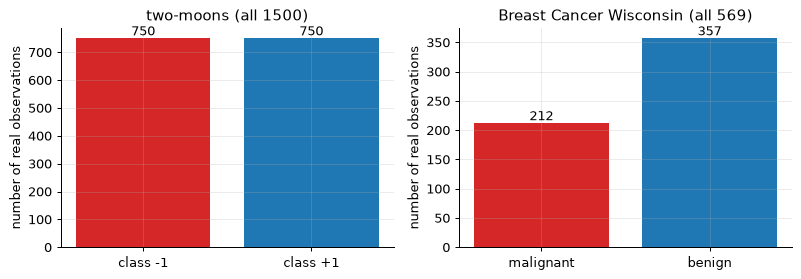

In [5]:
# ---------------------------------------------------------------- two-moons: shape, labels, counts
print("TWO-MOONS (paper's synthetic benchmark, generated with make_moons)")
print("full data  :", X_moons_raw.shape, "| feature names: ['x1', 'x2']")
def counts(v):
    u, c = np.unique(v, return_counts=True)
    return {int(a): int(b) for a, b in zip(u, c)}
print("original make_moons labels:", counts(y01_moons), "-> mapped to {-1, +1} for the hinge loss")
print("train (900):", counts(y_tr), "| test (600):", counts(y_te))

# ---------------------------------------------------------------- breast cancer: shape, labels, counts
print("\nBREAST CANCER WISCONSIN (real clinical data, used for V-C)")
print("full data  :", X_bc_full.shape)
print("feature names (30):", [str(f) for f in bc.feature_names])
print("original labels:", {str(n): int(c) for n, c in zip(bc.target_names, np.bincount(bc.target))},
      "(sklearn target 0 = malignant, 1 = benign) -> mapped to {-1, +1}")
print("train (398):", counts(BC_AUTH[2]), "| test (171):", counts(BC_AUTH[3]))

fig, ax = plt.subplots(1, 2, figsize=(9, 3.2))
for a, (title, labels, names, counts) in zip(ax, [
        ("two-moons (all 1500)", [-1, 1], ["class -1", "class +1"], [int((y_moons == -1).sum()), int((y_moons == 1).sum())]),
        ("Breast Cancer Wisconsin (all 569)", [-1, 1], list(bc.target_names), [int((y_bc_full == -1).sum()), int((y_bc_full == 1).sum())])]):
    bars = a.bar(names, counts, color=["tab:red", "tab:blue"])
    a.bar_label(bars)
    a.set_title(title); a.set_ylabel("number of real observations")
plt.tight_layout(); plt.show()

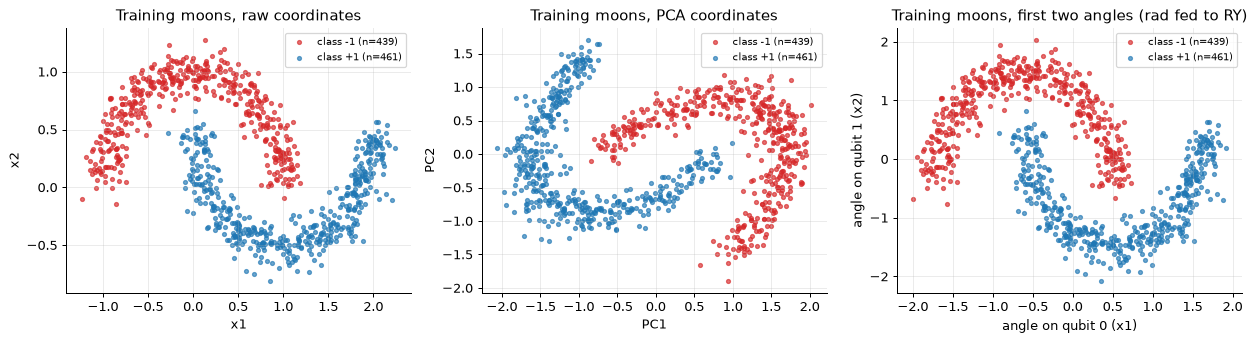

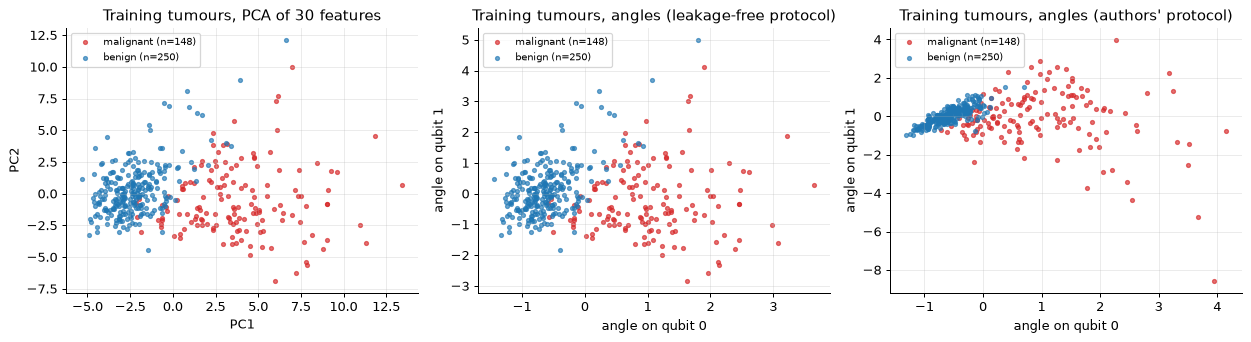

Both datasets are real/ground-truth labelled; the 2-D inputs of the 2-qubit circuit are exactly the angle plots above.


In [6]:
def scatter_classes(ax, Z, y, names, title, xl, yl):
    for lab, col, nm in zip([-1, 1], ["tab:red", "tab:blue"], names):
        m = y == lab
        ax.scatter(Z[m, 0], Z[m, 1], s=10, c=col, alpha=0.65, label=f"{nm} (n={m.sum()})")
    ax.set_title(title); ax.set_xlabel(xl); ax.set_ylabel(yl); ax.legend(loc="best", fontsize=8)

# ---------------------------------------------------------------- two-moons: raw / PCA / circuit angles
pca_m = PCA(n_components=2, random_state=SEED).fit(X_tr)             # fitted on the training split only
fig, ax = plt.subplots(1, 3, figsize=(14, 3.9))
scatter_classes(ax[0], X_tr_raw, y_tr, ["class -1", "class +1"], "Training moons, raw coordinates", "x1", "x2")
scatter_classes(ax[1], pca_m.transform(X_tr), y_tr, ["class -1", "class +1"], "Training moons, PCA coordinates", "PC1", "PC2")
scatter_classes(ax[2], X_tr, y_tr, ["class -1", "class +1"], "Training moons, first two angles (rad fed to RY)", "angle on qubit 0 (x1)", "angle on qubit 1 (x2)")
plt.tight_layout(); plt.show()

# ---------------------------------------------------------------- breast cancer: PCA of the 30 features / circuit angles
idx_tr = train_test_split(np.arange(len(X_bc_full)), test_size=0.3, random_state=SEED, stratify=y_bc_full)[0]
s0 = StandardScaler().fit(X_bc_full[idx_tr])                                            # training split only
pca_bc = PCA(n_components=2, random_state=SEED).fit(s0.transform(X_bc_full[idx_tr]))   # training split only
Z_bc_tr = pca_bc.transform(s0.transform(X_bc_full[idx_tr]))
fig, ax = plt.subplots(1, 3, figsize=(14, 3.9))
scatter_classes(ax[0], Z_bc_tr, y_bc_full[idx_tr], list(bc.target_names), "Training tumours, PCA of 30 features", "PC1", "PC2")
scatter_classes(ax[1], BC_CLEAN[0], BC_CLEAN[2], list(bc.target_names), "Training tumours, angles (leakage-free protocol)", "angle on qubit 0", "angle on qubit 1")
scatter_classes(ax[2], BC_AUTH[0], BC_AUTH[2], list(bc.target_names), "Training tumours, angles (authors' protocol)", "angle on qubit 0", "angle on qubit 1")
plt.tight_layout(); plt.show()
print("Both datasets are real/ground-truth labelled; the 2-D inputs of the 2-qubit circuit are exactly the angle plots above.")

## Quantum Circuit Architecture

The classifier is a 2-qubit variational circuit. The drawing below is the **circuit object that is actually executed** by the Qiskit Aer sampler later on: RY angle encoding of the two features, four trainable RY rotations around one CNOT, and a single-qubit Z-basis measurement. Gate order follows the authors' code (the paper only says "RY rotations and CNOT").

Because training runs 100 000+ circuit evaluations (SPSA, attacks, federated runs, repeated seeds), the optimisation loops use a tiny exact NumPy state-vector simulator of the same gate list. The cell after the drawing **asserts that this simulator equals Qiskit's `Statevector` of the drawn circuit** for 200 random inputs, and that the Aer sampler's shot counts agree with the simulator's probabilities. So every number below is a property of this circuit, not of a different model.

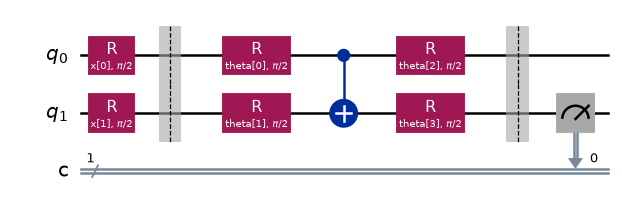

qubits               : 2
depth (no measure)   : 4   (paper Table III: 4)
depth (with measure) : 5
gate counts          : {'ry': 6, 'barrier': 2, 'cx': 1, 'measure': 1}
circuit parameters   : 6 = 2 data inputs + 4 trainable
trainable parameters : 4  (paper Table III: 4)
measured qubit       : 1 (Qiskit index; authors' operator label 'ZI')
NOTE: RY(x) followed by RY(theta) on the same qubit is RY(x + theta), so the first two trainable angles only shift the
      encoding; the model has 4 real trainable parameters but a 3-layer effective depth. This is a property of the paper's circuit.


In [7]:
x_par = ParameterVector("x", 2)          # the two features, used as rotation angles (radians)
t_par = ParameterVector("theta", 4)      # the four trainable parameters

def build_circuit(measure=True):
    qc = QuantumCircuit(N_QUBITS, 1 if measure else 0)
    qc.ry(x_par[0], 0); qc.ry(x_par[1], 1)       # angle encoding
    qc.barrier()
    qc.ry(t_par[0], 0); qc.ry(t_par[1], 1)       # CHOICE: order of the authors' code
    qc.cx(0, 1)                                  # entanglement
    qc.ry(t_par[2], 0); qc.ry(t_par[3], 1)
    if measure:
        qc.barrier()
        qc.measure(OBS_QUBIT, 0)                 # decision = sign of <Z> on this qubit
    return qc

qc_exec = build_circuit(measure=True)
fig = qc_exec.decompose().draw("mpl", fold=-1)    # decompose() shows the gates the sampler runs (no composite gates here)
display(fig)                                      # Qiskit closes its figure, so display it explicitly

qc_nomeas = build_circuit(measure=False)
print("qubits               :", qc_exec.num_qubits)
print("depth (no measure)   :", qc_nomeas.depth(), "  (paper Table III: 4)")
print("depth (with measure) :", qc_exec.depth())
print("gate counts          :", dict(qc_exec.count_ops()))
print("circuit parameters   :", qc_exec.num_parameters, "= 2 data inputs + 4 trainable")
print("trainable parameters :", len(t_par), " (paper Table III: 4)")
print("measured qubit       :", OBS_QUBIT, "(Qiskit index; authors' operator label 'ZI')")
print("NOTE: RY(x) followed by RY(theta) on the same qubit is RY(x + theta), so the first two trainable angles only shift the")
print("      encoding; the model has 4 real trainable parameters but a 3-layer effective depth. This is a property of the paper's circuit.")

In [8]:
# ---------------------------------------------------------------- exact simulator of the same gate list
def ry_mat(t):
    c, s = np.cos(t / 2), np.sin(t / 2)
    return np.array([[c, -s], [s, c]])

def expval(X, theta, qubit=None):
    # <Z> on `qubit` for every row of X (n, 2) of encoding angles; theta = 4 trainable angles
    qubit = OBS_QUBIT if qubit is None else qubit
    t0, t1 = X[:, 0] + theta[0], X[:, 1] + theta[1]               # RY(x) RY(theta) = RY(x + theta)
    a = np.stack([np.cos(t0 / 2), np.sin(t0 / 2)], 1)             # qubit 0 amplitudes
    b = np.stack([np.cos(t1 / 2), np.sin(t1 / 2)], 1)             # qubit 1 amplitudes
    psi = np.einsum("ni,nj->nji", a, b)                           # psi[n, q1, q0]
    psi2 = psi.copy()
    psi2[:, 0, 1], psi2[:, 1, 1] = psi[:, 1, 1], psi[:, 0, 1]     # CNOT(control q0, target q1)
    psi3 = np.einsum("ij,njk,lk->nil", ry_mat(theta[3]), psi2, ry_mat(theta[2]))
    p = np.abs(psi3) ** 2
    if qubit == 0:
        return p[:, :, 0].sum(1) - p[:, :, 1].sum(1)
    return p[:, 0, :].sum(1) - p[:, 1, :].sum(1)

def param_matrix(qc, X, theta):
    # columns ordered like qc.parameters (Qiskit sorts parameter names)
    cols = []
    for p in qc.parameters:
        cols.append(X[:, p.index] if p.vector.name == "x" else np.full(len(X), theta[p.index]))
    return np.column_stack(cols)

def qiskit_expval(X, theta, qubit=None):
    qubit = OBS_QUBIT if qubit is None else qubit
    P = param_matrix(qc_nomeas, X, theta)
    out = []
    for row in P:
        sv = Statevector(qc_nomeas.assign_parameters(dict(zip(qc_nomeas.parameters, row))))
        pr = sv.probabilities([qubit])
        out.append(pr[0] - pr[1])
    return np.array(out)

# ---------------------------------------------------------------- assertion 1: simulator == Qiskit Statevector
r_chk = np.random.default_rng(SEED)
Xc = r_chk.normal(size=(200, 2)); th_c = r_chk.uniform(-np.pi, np.pi, 4)
for q in (0, 1):
    err = np.max(np.abs(expval(Xc, th_c, q) - qiskit_expval(Xc, th_c, q)))
    assert err < 1e-10, err
    print(f"simulator vs Qiskit Statevector, measured qubit {q}: max |difference| = {err:.2e}  -> OK")

# ---------------------------------------------------------------- Aer sampler on the drawn circuit
def aer_counts_plus(X, theta, shots=SHOTS, seed=SEED):
    qcm = build_circuit(measure=True)
    sampler = AerSamplerV2(default_shots=shots, seed=seed)
    res = sampler.run([(qcm, param_matrix(qcm, X, theta))]).result()[0]
    bits = res.data.c
    return np.array([bits.get_counts(i).get("0", 0) for i in range(len(X))])      # bit 0 <-> Z = +1

k_chk = aer_counts_plus(Xc, th_c)
p_ex = (1 + expval(Xc, th_c)) / 2
dev = np.abs(k_chk - SHOTS * p_ex) / np.maximum(np.sqrt(SHOTS * p_ex * (1 - p_ex)), 1.0)
assert dev.max() < 5, dev.max()
print(f"Aer shot counts vs exact probabilities: max deviation {dev.max():.2f} sigma over 200 circuits -> OK (statistical agreement)")

simulator vs Qiskit Statevector, measured qubit 0: max |difference| = 5.55e-16  -> OK


simulator vs Qiskit Statevector, measured qubit 1: max |difference| = 6.66e-16  -> OK


Aer shot counts vs exact probabilities: max deviation 3.21 sigma over 200 circuits -> OK (statistical agreement)


## 4. Classical baselines on identical inputs

Before judging the quantum model, here is what ordinary classifiers achieve on the **same standardised two-moons inputs** (same training and test split). Two-moons is a 2-D toy problem, so a classical model is expected to be near perfect; this puts the paper's 87.5% in perspective. Logistic regression is also used later to ask whether entropy-based uncertainty is a quantum-specific effect.

In [9]:
baselines = {
    "Logistic regression": LogisticRegression(random_state=SEED),
    "SVC (RBF)": SVC(kernel="rbf", C=1.0, probability=True, random_state=SEED),
    "Random forest": RandomForestClassifier(n_estimators=200, random_state=SEED),
    "MLP (16,16)": MLPClassifier(hidden_layer_sizes=(16, 16), max_iter=800, random_state=SEED),   # CHOICE: size
}
rows = []
for name, mdl in baselines.items():
    t0 = time.time(); mdl.fit(X_tr, y_tr)
    rows.append({"model": name, "train acc": mdl.score(X_tr, y_tr), "test acc": mdl.score(X_te, y_te),
                 "test acc (first 100)": mdl.score(X_sub, y_sub), "fit time (s)": time.time() - t0})
df_base = pd.DataFrame(rows).set_index("model")
display(df_base.round(4))

,train acc,test acc,test acc (first 100),fit time (s)
model,,,,
Logistic regression,0.8833,0.9000,0.91,0.0162
SVC (RBF),0.9989,0.9967,1.00,0.1789
Random forest,1.0000,0.9850,1.00,3.4094
"MLP (16,16)",1.0000,0.9967,1.00,5.8281


## 5. Training the 2-qubit classifier with SPSA

Loss: squared hinge, `mean((1 - y * <Z>)^2)` with labels in {-1, +1}. Optimiser: SPSA, which estimates the gradient from two cost evaluations at `theta +- c * delta` with a random sign vector `delta`, and steps `theta <- theta - a * (cost+ - cost-) / (2 c delta)`. The gains `a` and `c` are constant (authors' code). Training uses the exact expectation value (as in the authors' code); finite shots enter in the uncertainty analysis.

SPSA, 50 iterations, 1.0s | trained parameters [-0.5851  0.1557 -0.1596  1.1417]
train accuracy 0.8389 | test accuracy with exact <Z> 0.8800


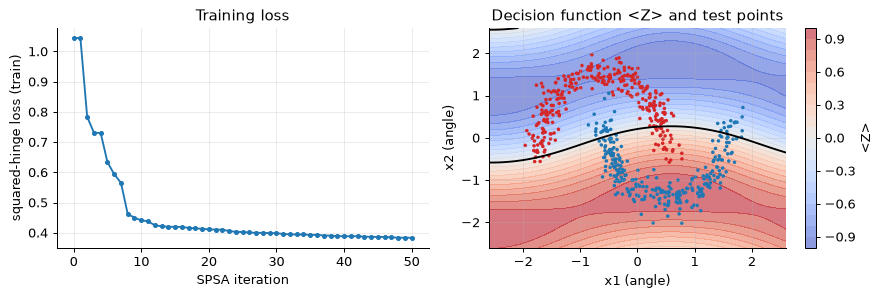

In [10]:
def sq_hinge(score, y):
    return np.mean((1.0 - y * score) ** 2)

def train_vqc(X, y, seed=SEED, qubit=None, iters=SPSA_ITERS, a=SPSA_A, c=SPSA_C, cost=None):
    # SPSA with Rademacher perturbations; returns final parameters and the cost history
    qubit = OBS_QUBIT if qubit is None else qubit
    rs = np.random.RandomState(seed)                     # legacy generator on purpose: same stream as the authors' np.random.seed(seed)
    theta = rs.randn(4) * INIT_SCALE
    cost = cost or (lambda t: sq_hinge(expval(X, t, qubit), y))
    hist = [cost(theta)]
    for _ in range(iters):
        d = rs.choice([-1, 1], size=theta.size)
        g = (cost(theta + c * d) - cost(theta - c * d)) / (2 * c * d)
        theta = theta - a * g
        hist.append(cost(theta))
    return theta, np.array(hist)

def predict_sign(score):
    return np.where(score > 0, 1, -1)

t0 = time.time()
theta_star, hist = train_vqc(X_tr, y_tr, seed=SEED)
acc_tr = np.mean(predict_sign(expval(X_tr, theta_star)) == y_tr)
acc_te_exact = np.mean(predict_sign(expval(X_te, theta_star)) == y_te)
print(f"SPSA, {SPSA_ITERS} iterations, {time.time()-t0:.1f}s | trained parameters {np.round(theta_star, 4)}")
print(f"train accuracy {acc_tr:.4f} | test accuracy with exact <Z> {acc_te_exact:.4f}")
assert np.max(np.abs(expval(X_te[:50], theta_star) - qiskit_expval(X_te[:50], theta_star))) < 1e-10   # trained model == Qiskit circuit

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].plot(hist, marker="o", ms=3); ax[0].set_xlabel("SPSA iteration"); ax[0].set_ylabel("squared-hinge loss (train)")
ax[0].set_title("Training loss")
xx, yy = np.meshgrid(np.linspace(-2.6, 2.6, 160), np.linspace(-2.6, 2.6, 160))
zz = expval(np.c_[xx.ravel(), yy.ravel()], theta_star).reshape(xx.shape)
cs = ax[1].contourf(xx, yy, zz, levels=np.linspace(-1, 1, 21), cmap="coolwarm", alpha=0.6)
ax[1].contour(xx, yy, zz, levels=[0], colors="k", linewidths=1.5)
ax[1].scatter(X_te[:, 0], X_te[:, 1], c=np.where(y_te == 1, "tab:blue", "tab:red"), s=8, edgecolor="none")
ax[1].set_title("Decision function <Z> and test points"); ax[1].set_xlabel("x1 (angle)"); ax[1].set_ylabel("x2 (angle)")
plt.colorbar(cs, ax=ax[1], label="<Z>"); plt.tight_layout(); plt.show()

## 6. Experiment V-A: uncertainty quantification

Each test sample is sent through the circuit **200 times** (shots). The fraction of shots with outcome +1 gives `p(+1|x)`; the prediction is the sign of the mean outcome, and four uncertainty scores follow from the shot distribution: predictive entropy (bits), variation ratio `1 - max_y p(y|x)`, standard deviation of the +-1 outcomes and max confidence. The paper's question: are these scores higher when the prediction is wrong?

Here the 200 shots come from the **Qiskit Aer sampler running the drawn circuit** (seeded).

In [11]:
def unc_metrics(k_plus, shots):
    # k_plus: number of +1 outcomes out of `shots`
    k_plus = np.asarray(k_plus, dtype=float)
    p = k_plus / shots
    pr = np.stack([1 - p, p], 1)
    return {"p_plus": p,
            "pred": np.where(2 * p - 1 > 0, 1, -1),                  # sign of the mean outcome (ties -> -1, as in the authors' code)
            "entropy": -(pr * np.log2(pr + 1e-10)).sum(1),           # CHOICE: bits
            "var_ratio": 1 - np.maximum(p, 1 - p),
            "std": 2 * np.sqrt(p * (1 - p)),                         # population std of the +-1 outcomes
            "max_conf": np.maximum(p, 1 - p)}

def compare_groups(vals, correct):
    c, i = vals[correct], vals[~correct]
    nc, ni = len(c), len(i)
    if ni < 2:
        return {k: np.nan for k in ["correct_mean", "correct_std", "incorrect_mean", "incorrect_std", "delta", "cohen_d", "t", "p"]}
    pooled = np.sqrt(((nc - 1) * c.std() ** 2 + (ni - 1) * i.std() ** 2) / (nc + ni - 2))
    t, p = stats.ttest_ind(i, c)
    return {"correct_mean": c.mean(), "correct_std": c.std(), "incorrect_mean": i.mean(), "incorrect_std": i.std(),
            "delta": i.mean() - c.mean(), "cohen_d": (i.mean() - c.mean()) / pooled if pooled > 0 else np.nan, "t": t, "p": p}

t0 = time.time()
k_aer = aer_counts_plus(X_te, theta_star, shots=SHOTS, seed=SEED)            # 600 circuits x 200 shots on the drawn circuit
M = unc_metrics(k_aer, SHOTS)
correct = M["pred"] == y_te
n_ok, n_bad = int(correct.sum()), int((~correct).sum())
print(f"Aer sampling of {len(X_te)} circuits x {SHOTS} shots: {time.time()-t0:.1f}s")

# --- Table III analogue
table3 = pd.DataFrame({"This notebook": {
    "Total test samples": len(X_te), "Training samples": len(X_tr), "Features": 2, "Classes": 2,
    "Correct predictions": n_ok, "Incorrect predictions": n_bad, "Test accuracy (200-shot sign)": n_ok / len(X_te),
    "Test accuracy (exact <Z>)": acc_te_exact, "Qubits": 2, "Circuit depth": qc_nomeas.depth(),
    "Trainable parameters": 4, "Shot count": SHOTS},
    "Paper (Table III)": {"Total test samples": 600, "Training samples": 900, "Features": 2, "Classes": 2,
    "Correct predictions": 525, "Incorrect predictions": 75, "Test accuracy (200-shot sign)": 0.875,
    "Test accuracy (exact <Z>)": np.nan, "Qubits": 2, "Circuit depth": 4, "Trainable parameters": 4, "Shot count": 200}})
display(table3.astype(object).map(lambda v: "" if pd.isna(v) else (f"{v:.4f}" if v < 1.5 else f"{int(v)}")))

# --- Table IV analogue
names = {"entropy": "Predictive entropy", "var_ratio": "Variation ratio", "std": "Standard deviation", "max_conf": "Max confidence"}
paper_t4 = {"entropy": (0.471, 0.316, 0.900, 0.138, 1.434), "var_ratio": (0.139, 0.137, 0.359, 0.111, 1.645),
            "std": (0.568, 0.285, 0.928, 0.103, 1.340), "max_conf": (0.861, 0.137, 0.641, 0.111, -1.645)}
rows = []
for key, nm in names.items():
    r = compare_groups(M[key], correct)
    pp = paper_t4[key]
    rows.append({"metric": nm, "correct (ours)": f"{r['correct_mean']:.3f} +- {r['correct_std']:.3f}",
                 "incorrect (ours)": f"{r['incorrect_mean']:.3f} +- {r['incorrect_std']:.3f}",
                 "delta (ours)": r["delta"], "Cohen d (ours)": r["cohen_d"], "t (ours)": r["t"], "p (ours)": r["p"],
                 "correct (paper)": f"{pp[0]:.3f} +- {pp[1]:.3f}", "incorrect (paper)": f"{pp[2]:.3f} +- {pp[3]:.3f}", "Cohen d (paper)": pp[4]})
table4 = pd.DataFrame(rows).set_index("metric")
display(table4.round(4))
STAT_ENT = compare_groups(M["entropy"], correct)

Aer sampling of 600 circuits x 200 shots: 69.7s


,This notebook,Paper (Table III)
Total test samples,600,600
Training samples,900,900
Features,2,2
Classes,2,2
Correct predictions,524,525
Incorrect predictions,76,75
Test accuracy (200-shot sign),0.8733,0.8750
Test accuracy (exact <Z>),0.8800,
Qubits,2,2
Circuit depth,4,4


,correct (ours),incorrect (ours),delta (ours),Cohen d (ours),t (ours),p (ours),correct (paper),incorrect (paper),Cohen d (paper)
metric,,,,,,,,,
Predictive entropy,0.474 +- 0.315,0.903 +- 0.129,0.4296,1.4401,11.7193,0.0,0.471 +- 0.316,0.900 +- 0.138,1.434
Variation ratio,0.141 +- 0.139,0.360 +- 0.107,0.2190,1.6212,13.1891,0.0,0.139 +- 0.137,0.359 +- 0.111,1.645
Standard deviation,0.570 +- 0.285,0.930 +- 0.096,0.3602,1.3423,10.9245,0.0,0.568 +- 0.285,0.928 +- 0.103,1.340
Max confidence,0.859 +- 0.139,0.640 +- 0.107,-0.2190,-1.6212,-13.1891,0.0,0.861 +- 0.137,0.641 +- 0.111,-1.645


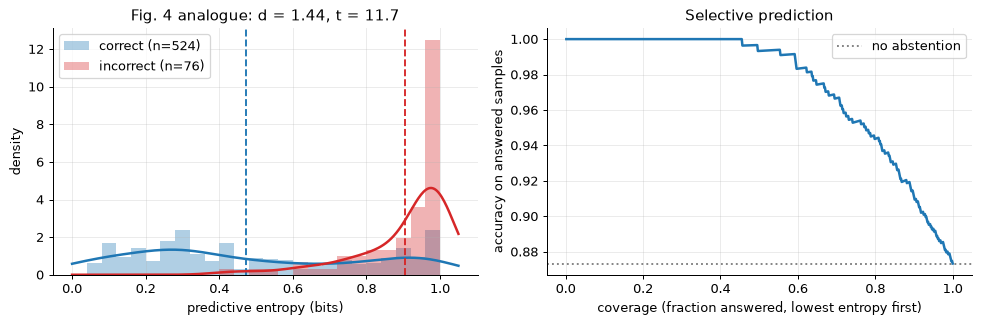

Abstaining when entropy > 0.7: rejects 90.8% of the errors and keeps 70.2% of the correct predictions
(paper: 'would reject most errors while retaining the majority of correct predictions'); selected accuracy 0.981 vs 0.873


In [12]:
# --- Figure 4 analogue: entropy distribution of correct vs incorrect predictions
ent_c, ent_i = M["entropy"][correct], M["entropy"][~correct]
grid = np.linspace(0, 1.05, 300)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.7))
ax[0].hist(ent_c, bins=25, range=(0, 1), density=True, alpha=0.35, color="tab:blue", label=f"correct (n={len(ent_c)})")
ax[0].hist(ent_i, bins=25, range=(0, 1), density=True, alpha=0.35, color="tab:red", label=f"incorrect (n={len(ent_i)})")
for v, col in [(ent_c, "tab:blue"), (ent_i, "tab:red")]:
    if len(v) > 2 and v.std() > 0:
        ax[0].plot(grid, stats.gaussian_kde(v)(grid), color=col, lw=2)
    ax[0].axvline(v.mean(), color=col, ls="--")
ax[0].set_xlabel("predictive entropy (bits)"); ax[0].set_ylabel("density")
ax[0].set_title(f"Fig. 4 analogue: d = {STAT_ENT['cohen_d']:.2f}, t = {STAT_ENT['t']:.1f}"); ax[0].legend()

# selective prediction: abstain when entropy > threshold; risk-coverage curve
abstain = M["entropy"] > ENTROPY_THRESHOLD
err_rejected = abstain[~correct].mean() if n_bad else np.nan
correct_kept = (~abstain)[correct].mean()
order = np.argsort(M["entropy"], kind="stable")
cov = np.arange(1, len(order) + 1) / len(order)
acc_at_cov = np.cumsum(correct[order]) / np.arange(1, len(order) + 1)
ax[1].plot(cov, acc_at_cov, lw=2); ax[1].axhline(correct.mean(), color="gray", ls=":", label="no abstention")
ax[1].set_xlabel("coverage (fraction answered, lowest entropy first)"); ax[1].set_ylabel("accuracy on answered samples")
ax[1].set_title("Selective prediction"); ax[1].legend(); plt.tight_layout(); plt.show()
print(f"Abstaining when entropy > {ENTROPY_THRESHOLD}: rejects {err_rejected:.1%} of the errors and keeps {correct_kept:.1%} of the correct predictions")
print(f"(paper: 'would reject most errors while retaining the majority of correct predictions'); selected accuracy {correct[~abstain].mean():.3f} vs {correct.mean():.3f}")

,initial,final,change %,r with shots,p,initial (paper),final (paper),r (paper)
accuracy,0.8750,0.8783,0.3810,0.2810,0.0,0.8733,0.8783,0.2215
entropy,0.5174,0.5296,2.3594,0.5988,0.0,0.5126,0.5281,0.5780
var_ratio,0.1665,0.1681,0.9652,0.3729,0.0,0.1628,0.1680,0.3887
confidence,0.8335,0.8319,-0.1928,-0.3729,0.0,0.8372,0.8320,-0.3887


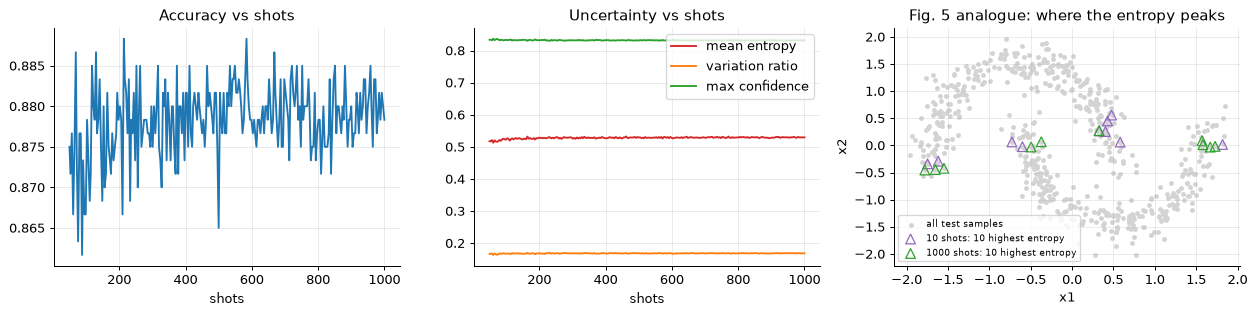

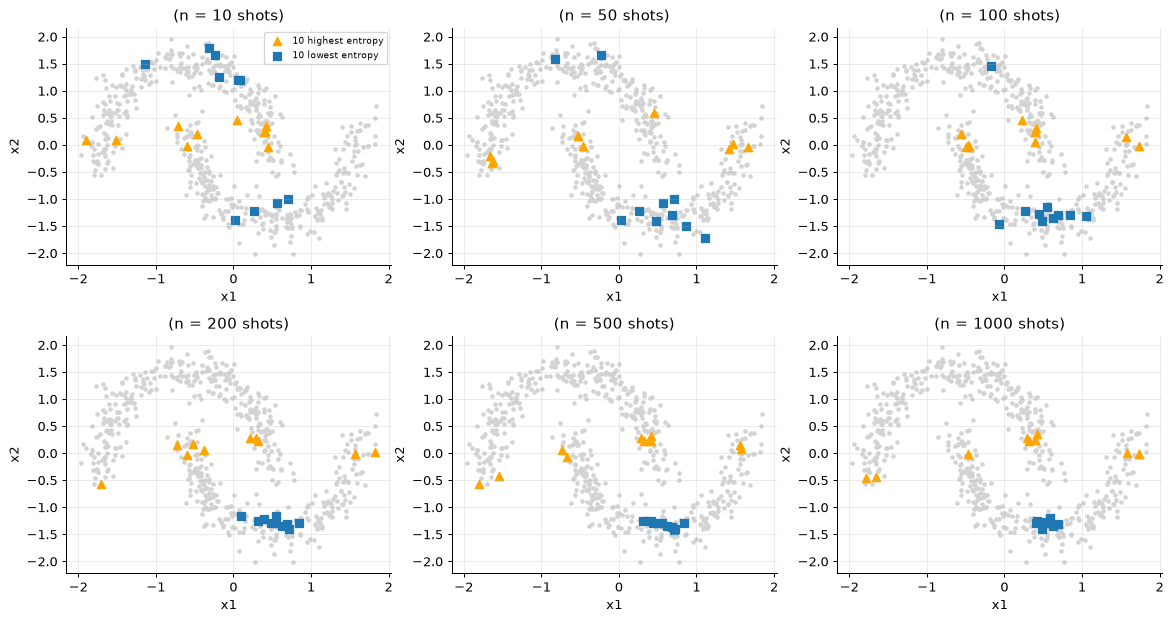

In [13]:
# --- Table VI analogue (accuracy and uncertainty versus number of shots) and Figure 5 analogue
# the sweep draws binomial shots from the exact probability (validated against Aer above)
r_shots = np.random.default_rng(SEED)
p_exact = (1 + expval(X_te, theta_star)) / 2
rows = []
for n in SHOT_GRID:
    m = unc_metrics(r_shots.binomial(n, p_exact), n)
    rows.append({"shots": n, "accuracy": np.mean(m["pred"] == y_te), "entropy": m["entropy"].mean(),
                 "var_ratio": m["var_ratio"].mean(), "confidence": m["max_conf"].mean()})
df_shots = pd.DataFrame(rows)

def row6(col):
    r, pv = stats.pearsonr(df_shots["shots"], df_shots[col])
    a0, a1 = df_shots[col].iloc[0], df_shots[col].iloc[-1]
    return {"initial": a0, "final": a1, "change %": 100 * (a1 - a0) / a0, "r with shots": r, "p": pv}
table6 = pd.DataFrame({k: row6(k) for k in ["accuracy", "entropy", "var_ratio", "confidence"]}).T
paper6 = pd.DataFrame({"accuracy": [0.8733, 0.8783, 0.2215], "entropy": [0.5126, 0.5281, 0.5780],
                       "var_ratio": [0.1628, 0.1680, 0.3887], "confidence": [0.8372, 0.8320, -0.3887]},
                      index=["initial (paper)", "final (paper)", "r (paper)"]).T
display(pd.concat([table6.round(4), paper6], axis=1))

fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
ax[0].plot(df_shots["shots"], df_shots["accuracy"]); ax[0].set_title("Accuracy vs shots"); ax[0].set_xlabel("shots")
ax[1].plot(df_shots["shots"], df_shots["entropy"], color="tab:red", label="mean entropy")
ax[1].plot(df_shots["shots"], df_shots["var_ratio"], color="tab:orange", label="variation ratio")
ax[1].plot(df_shots["shots"], df_shots["confidence"], color="tab:green", label="max confidence")
ax[1].legend(); ax[1].set_title("Uncertainty vs shots"); ax[1].set_xlabel("shots")
# Figure 5: spatial map of uncertainty for a few shot counts
n_show = SHOT_PANELS[0], SHOT_PANELS[-1]
for n, col in zip(n_show, ["tab:purple", "tab:green"]):
    m = unc_metrics(r_shots.binomial(n, p_exact), n)
    hi, lo = np.argsort(-m["entropy"])[:10], np.argsort(m["entropy"])[:10]
    if col == "tab:purple":
        ax[2].scatter(X_te[:, 0], X_te[:, 1], c="lightgray", s=8, label="all test samples")
    ax[2].scatter(X_te[hi, 0], X_te[hi, 1], marker="^", s=60, facecolor="none", edgecolor=col, label=f"{n} shots: 10 highest entropy")
ax[2].legend(fontsize=7); ax[2].set_title("Fig. 5 analogue: where the entropy peaks"); ax[2].set_xlabel("x1"); ax[2].set_ylabel("x2")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax_, n in zip(axes.ravel(), SHOT_PANELS):
    m = unc_metrics(r_shots.binomial(n, p_exact), n)
    hi, lo = np.argsort(-m["entropy"], kind="stable")[:10], np.argsort(m["entropy"], kind="stable")[:10]
    ax_.scatter(X_te[:, 0], X_te[:, 1], c="lightgray", s=7)
    ax_.scatter(X_te[hi, 0], X_te[hi, 1], marker="^", c="orange", s=45, label="10 highest entropy")
    ax_.scatter(X_te[lo, 0], X_te[lo, 1], marker="s", c="tab:blue", s=35, label="10 lowest entropy")
    ax_.set_title(f"(n = {n} shots)"); ax_.set_xlabel("x1"); ax_.set_ylabel("x2")
axes[0, 0].legend(fontsize=7); plt.tight_layout(); plt.show()

In [14]:
# --- robustness of the V-A conclusions: several independent training seeds, and the observable-qubit ablation
rows = []
for s in range(N_SEEDS):
    seed_s = SEED + s
    th_s, _ = train_vqc(X_tr, y_tr, seed=seed_s)
    p_s = (1 + expval(X_te, th_s)) / 2
    m_s = unc_metrics(np.random.default_rng(seed_s).binomial(SHOTS, p_s), SHOTS)
    c_s = m_s["pred"] == y_te
    st = compare_groups(m_s["entropy"], c_s)
    rows.append({"seed": seed_s, "exact acc": np.mean(predict_sign(expval(X_te, th_s)) == y_te), "200-shot acc": c_s.mean(),
                 "entropy correct": st["correct_mean"], "entropy incorrect": st["incorrect_mean"], "Cohen d": st["cohen_d"]})
df_seeds = pd.DataFrame(rows).set_index("seed")
display(df_seeds.round(4))
print("mean +- std over seeds:\n", df_seeds.agg(["mean", "std"]).round(4).to_string())

abl = []
for q in (0, 1):
    th_q, _ = train_vqc(X_tr, y_tr, seed=SEED, qubit=q)
    abl.append({"measured Qiskit qubit": q, "exact test acc": np.mean(predict_sign(expval(X_te, th_q, q)) == y_te),
                "200-shot test acc": np.mean(unc_metrics(np.random.default_rng(SEED).binomial(SHOTS, (1 + expval(X_te, th_q, q)) / 2), SHOTS)["pred"] == y_te)})
display(pd.DataFrame(abl).set_index("measured Qiskit qubit").round(4))

# --- classical baseline: is entropy-based error detection quantum specific?
lr = baselines["Logistic regression"]
pr_lr = lr.predict_proba(X_te)[:, 1]
ent_lr = -(np.stack([1 - pr_lr, pr_lr], 1) * np.log2(np.stack([1 - pr_lr, pr_lr], 1) + 1e-10)).sum(1)
corr_lr = lr.predict(X_te) == y_te
st_lr = compare_groups(ent_lr, corr_lr)
print(f"Logistic regression on the same inputs: accuracy {corr_lr.mean():.3f}, entropy correct {st_lr['correct_mean']:.3f} vs incorrect {st_lr['incorrect_mean']:.3f}, Cohen d = {st_lr['cohen_d']:.2f}")
print("-> a classical model's probability entropy separates its errors just as well: uncertainty scores track the distance to the decision boundary, they are not a quantum feature.")

,exact acc,200-shot acc,entropy correct,entropy incorrect,Cohen d
seed,,,,,
42,0.8800,0.8817,0.4774,0.8912,1.3577
43,0.8833,0.8733,0.4709,0.9096,1.4618
44,0.8667,0.8650,0.5497,0.9029,1.3532
45,0.8750,0.8800,0.5117,0.8937,1.3742
46,0.8783,0.8783,0.4911,0.8891,1.3944
47,0.8767,0.8833,0.4765,0.8968,1.3895
48,0.8833,0.8750,0.4830,0.8942,1.4110
49,0.8850,0.8833,0.4810,0.8959,1.4070
50,0.8783,0.8750,0.4713,0.9002,1.4519


mean +- std over seeds:
       exact acc  200-shot acc  entropy correct  entropy incorrect  Cohen d
mean     0.8777        0.8765           0.4868             0.8985   1.4056
std      0.0059        0.0060           0.0265             0.0074   0.0397


,exact test acc,200-shot test acc
measured Qiskit qubit,,
0,0.885,0.8783
1,0.880,0.8817


Logistic regression on the same inputs: accuracy 0.900, entropy correct 0.344 vs incorrect 0.792, Cohen d = 1.50
-> a classical model's probability entropy separates its errors just as well: uncertainty scores track the distance to the decision boundary, they are not a quantum feature.


## 7. Experiment V-B: adversarial robustness

**Threat model.** A white-box attacker perturbs the *classical input* `x` (the two features that become rotation angles) inside an L-infinity ball of radius `eps`. We implement the three attacks the paper reports:

- **FGSM:** `x_adv = x + eps * sign(grad_x L)`, with `L` the squared-hinge loss.
- **PGD:** 10 steps of size `eps/10`, projected onto the L-infinity ball (no random start; with this step size the ten steps can move at most `eps` in total, so PGD behaves almost like FGSM, which is exactly what the paper observes).
- **Quantum-state perturbation:** uniform noise in `[-eps, eps]` added directly to the encoding angles (a random, non-gradient perturbation).

The input gradient is a forward finite difference of the loss (step 0.01), as in the authors' code, and the classifier output is the exact `<Z>`. Metrics: robust accuracy, accuracy drop (clean minus robust) and attack success rate. The paper *defines* success as "the fraction of correctly classified clean samples that are misclassified after perturbation", but the authors' code divides by *all* samples; we compute both. The V-B figures use the **first 100 test samples**, like the paper; we also report all 600.

In [15]:
def loss_vec(score, y):
    return (1.0 - y * score) ** 2

def input_grad(score_fn, X, y, h=FD_STEP):
    # forward finite difference of the squared-hinge loss w.r.t. each input coordinate (authors' code)
    base = loss_vec(score_fn(X), y)
    g = np.zeros_like(X)
    for i in range(X.shape[1]):
        Xp = X.copy(); Xp[:, i] += h
        g[:, i] = (loss_vec(score_fn(Xp), y) - base) / h
    return g

def attack_fgsm(score_fn, X, y, eps):
    return X + eps * np.sign(input_grad(score_fn, X, y))

def attack_pgd(score_fn, X, y, eps, steps=PGD_STEPS):
    alpha = eps / steps
    Xa = X.copy()
    for _ in range(steps):
        Xa = Xa + alpha * np.sign(input_grad(score_fn, Xa, y))
        Xa = X + np.clip(Xa - X, -eps, eps)                  # project onto the L-infinity ball
    return Xa

def attack_qstate(score_fn, X, y, eps, rs):
    return X + rs.uniform(-eps, eps, size=X.shape)

def eval_adv(score_fn, X, y, Xa):
    p0, p1 = predict_sign(score_fn(X)), predict_sign(score_fn(Xa))
    ok0, ok1 = p0 == y, p1 == y
    flipped = (ok0 & ~ok1).sum()
    return {"clean": ok0.mean(), "robust": ok1.mean(), "drop": ok0.mean() - ok1.mean(),
            "asr_text": flipped / max(ok0.sum(), 1), "asr_code": flipped / len(y)}

def run_attack(name, score_fn, X, y, eps, repeats=1):
    if name == "FGSM":
        return eval_adv(score_fn, X, y, attack_fgsm(score_fn, X, y, eps))
    if name == "PGD":
        return eval_adv(score_fn, X, y, attack_pgd(score_fn, X, y, eps))
    outs = [eval_adv(score_fn, X, y, attack_qstate(score_fn, X, y, eps, np.random.RandomState(SEED + r))) for r in range(repeats)]
    return {k: float(np.mean([o[k] for o in outs])) for k in outs[0]}

ATTACKS = ["FGSM", "PGD", "Quantum-State"]
def sweep(score_fn, X, y, eps_list):
    rows = []
    for eps in eps_list:
        for a in ATTACKS:
            r = run_attack(a, score_fn, X, y, eps, repeats=Q_REPEATS)
            rows.append({"attack": a, "eps": eps, **r})
    return pd.DataFrame(rows)

score_q = lambda X: expval(X, theta_star)
t0 = time.time()
df_dense = sweep(score_q, X_sub, y_sub, EPS_DENSE)           # 100-sample subset, dense grid (Figures 6, 7, 10)
df_p100 = sweep(score_q, X_sub, y_sub, EPS_PAPER)            # 100-sample subset, the paper's 7 budgets (Table VIII)
df_p600 = sweep(score_q, X_te, y_te, EPS_PAPER)              # all 600 test samples
print(f"attacks done in {time.time()-t0:.1f}s | clean accuracy on the 100-sample subset: {df_dense['clean'].iloc[0]:.3f}, on all 600: {df_p600['clean'].iloc[0]:.3f}  (paper: 0.880)")

# --- Table VIII analogue
def table8(df):
    g = df.groupby("attack", sort=False)[["drop", "clean", "robust"]].mean()
    g.columns = ["Acc. drop", "Clean acc.", "Robust acc."]
    return g
t8 = pd.concat({"100 samples (ours)": table8(df_p100), "600 samples (ours)": table8(df_p600),
                "paper": pd.DataFrame({"Acc. drop": [0.069, 0.069, -0.004], "Clean acc.": [0.880] * 3, "Robust acc.": [0.811, 0.811, 0.884]},
                                      index=["FGSM", "PGD", "Quantum-State"])}, axis=1)
display(t8.round(4))
g_dense = df_dense.groupby("attack", sort=False)[["drop", "clean", "robust"]].mean()
print("Mean over the DENSE 50-point grid of the authors' code (the Table VIII caption says 7 budgets):")
display(g_dense.round(4).rename(columns={"drop": "Acc. drop", "clean": "Clean acc.", "robust": "Robust acc."}))

attacks done in 9.3s | clean accuracy on the 100-sample subset: 0.880, on all 600: 0.880  (paper: 0.880)


100 samples (ours)                        600 samples (ours)  \
                       Acc. drop Clean acc. Robust acc.          Acc. drop   
FGSM                      0.0543       0.88      0.8257             0.0852   
PGD                       0.0543       0.88      0.8257             0.0857   
Quantum-State             0.0004       0.88      0.8796             0.0075   

                                         paper                         
              Clean acc. Robust acc. Acc. drop Clean acc. Robust acc.  
FGSM                0.88      0.7948     0.069       0.88       0.811  
PGD                 0.88      0.7943     0.069       0.88       0.811  
Quantum-State       0.88      0.8725    -0.004       0.88       0.884

Mean over the DENSE 50-point grid of the authors' code (the Table VIII caption says 7 budgets):


,Acc. drop,Clean acc.,Robust acc.
attack,,,
FGSM,0.0686,0.88,0.8114
PGD,0.0688,0.88,0.8112
Quantum-State,-0.0028,0.88,0.8828


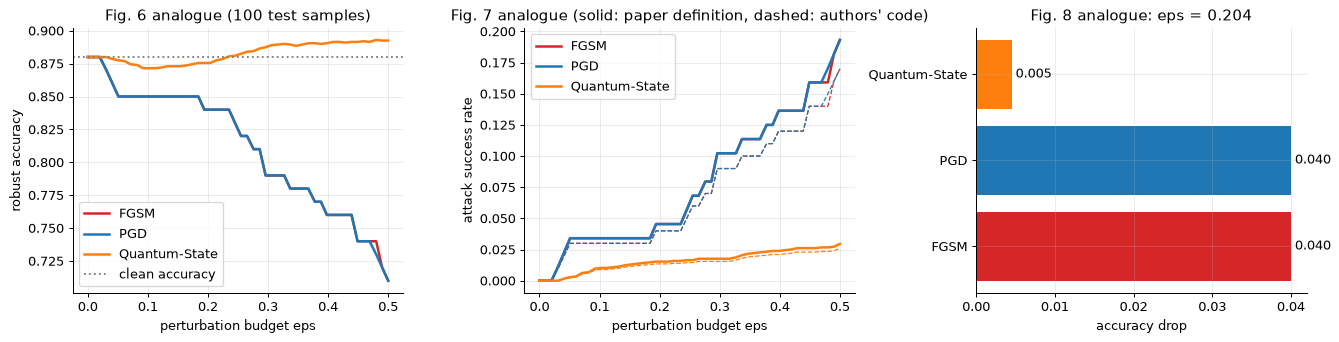

PGD at eps = 0.5: robust accuracy 0.710 (drop 0.170); paper: about 0.71 (drop about 0.17)
Attack success at eps = 0.5, PGD: paper definition 0.193, authors' code definition 0.170; paper: about 0.18
accuracy drop at eps = 0.204: {'FGSM': np.float64(0.04), 'PGD': np.float64(0.04), 'Quantum-State': 0.005} | paper: FGSM 0.040, PGD 0.040, quantum-state 0.010


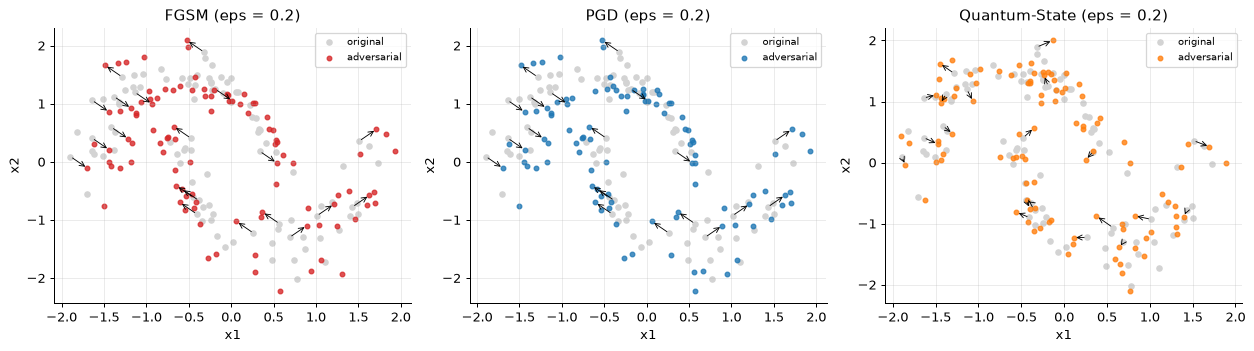

In [16]:
# --- Figure 6 (robust accuracy) and Figure 7 (attack success rate)
col = {"FGSM": "tab:red", "PGD": "tab:blue", "Quantum-State": "tab:orange"}
fig, ax = plt.subplots(1, 3, figsize=(15, 3.9))
for a in ATTACKS:
    d = df_dense[df_dense.attack == a]
    ax[0].plot(d.eps, d.robust, label=a, color=col[a], lw=2)
    ax[1].plot(d.eps, d.asr_text, label=a, color=col[a], lw=2)
    ax[1].plot(d.eps, d.asr_code, color=col[a], lw=1, ls="--")
ax[0].axhline(df_dense.clean.iloc[0], color="gray", ls=":", label="clean accuracy")
ax[0].set_xlabel("perturbation budget eps"); ax[0].set_ylabel("robust accuracy"); ax[0].set_title("Fig. 6 analogue (100 test samples)"); ax[0].legend()
ax[1].set_xlabel("perturbation budget eps"); ax[1].set_ylabel("attack success rate")
ax[1].set_title("Fig. 7 analogue (solid: paper definition, dashed: authors' code)"); ax[1].legend()
d8 = {a: run_attack(a, score_q, X_sub, y_sub, EPS_REP, repeats=Q_REPEATS) for a in ATTACKS}
ax[2].barh(list(d8), [d8[a]["drop"] for a in d8], color=[col[a] for a in d8])
for i, a in enumerate(d8):
    ax[2].text(d8[a]["drop"], i, f" {d8[a]['drop']:.3f}", va="center")
ax[2].set_xlabel("accuracy drop"); ax[2].set_title(f"Fig. 8 analogue: eps = {EPS_REP}"); plt.tight_layout(); plt.show()
mx = df_dense[df_dense.attack == "PGD"]
print(f"PGD at eps = 0.5: robust accuracy {mx.robust.iloc[-1]:.3f} (drop {mx['drop'].iloc[-1]:.3f}); paper: about 0.71 (drop about 0.17)")
print(f"Attack success at eps = 0.5, PGD: paper definition {mx.asr_text.iloc[-1]:.3f}, authors' code definition {mx.asr_code.iloc[-1]:.3f}; paper: about 0.18")
print("accuracy drop at eps = 0.204:", {a: round(d8[a]['drop'], 3) for a in d8}, "| paper: FGSM 0.040, PGD 0.040, quantum-state 0.010")

# --- Figure 9 analogue: where do the adversarial examples go (eps = 0.2)
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
r9 = np.random.RandomState(SEED)
for a_, name, Xa in zip(ax, ATTACKS, [attack_fgsm(score_q, X_sub, y_sub, 0.2), attack_pgd(score_q, X_sub, y_sub, 0.2),
                                       attack_qstate(score_q, X_sub, y_sub, 0.2, r9)]):
    a_.scatter(X_sub[:, 0], X_sub[:, 1], c="lightgray", s=18, label="original")
    a_.scatter(Xa[:, 0], Xa[:, 1], c=col[name], s=14, alpha=0.8, label="adversarial")
    for i in range(0, len(X_sub), 5):
        a_.annotate("", xy=Xa[i], xytext=X_sub[i], arrowprops=dict(arrowstyle="->", color="k", lw=0.7))
    a_.set_title(f"{name} (eps = 0.2)"); a_.set_xlabel("x1"); a_.set_ylabel("x2"); a_.legend(fontsize=8)
plt.tight_layout(); plt.show()

### Classical baselines under the same attacks

The same FGSM and PGD (same finite-difference gradient of the same loss) are applied to the classical baselines on the identical standardised inputs. Models without a usable gradient (random forest: piecewise-constant probabilities) show *gradient masking*, not robustness. This tells us whether the quantum classifier is unusually fragile or merely a small low-capacity model near a decision boundary.

In [17]:
def classical_score(m, name):
    if name in ("Logistic regression", "SVC (RBF)"):
        return lambda X: m.decision_function(X)
    return lambda X: 2 * m.predict_proba(X)[:, 1] - 1

rows = []
for name, m in baselines.items():
    sf = classical_score(m, name)
    for eps in (0.1, 0.2, 0.3, 0.5):
        for a in ("FGSM", "PGD"):
            r = run_attack(a, sf, X_sub, y_sub, eps)
            rows.append({"model": name, "attack": a, "eps": eps, "clean": r["clean"], "robust": r["robust"]})
for eps in (0.1, 0.2, 0.3, 0.5):
    for a in ("FGSM", "PGD"):
        r = run_attack(a, score_q, X_sub, y_sub, eps)
        rows.append({"model": "2-qubit VQC", "attack": a, "eps": eps, "clean": r["clean"], "robust": r["robust"]})
df_cl = pd.DataFrame(rows)
display(df_cl.pivot_table(index=["model", "attack"], columns="eps", values="robust").round(3))
print("clean accuracy on the 100-sample subset:", df_cl.groupby("model")["clean"].first().round(3).to_dict())

eps                          0.1   0.2   0.3   0.5
model               attack                        
2-qubit VQC         FGSM    0.85  0.84  0.79  0.71
                    PGD     0.85  0.84  0.79  0.71
Logistic regression FGSM    0.88  0.85  0.84  0.84
                    PGD     0.88  0.85  0.84  0.84
MLP (16,16)         FGSM    1.00  0.98  0.87  0.51
                    PGD     1.00  0.98  0.86  0.44
Random forest       FGSM    0.99  0.98  0.97  0.95
                    PGD     1.00  1.00  0.99  0.98
SVC (RBF)           FGSM    1.00  0.97  0.92  0.91
                    PGD     1.00  0.97  0.92  0.90

clean accuracy on the 100-sample subset: {'2-qubit VQC': 0.88, 'Logistic regression': 0.91, 'MLP (16,16)': 1.0, 'Random forest': 1.0, 'SVC (RBF)': 1.0}


### Adversarial training, Lipschitz constant, transferability and vulnerability map

The paper trains a second model on FGSM examples at `eps = 0.15` (inside every SPSA cost evaluation the training points are first attacked with FGSM against the *current* parameters), compares the two models (Table IX, Figure 10), estimates a Lipschitz constant, measures transferability of adversarial examples from the standard to the robust model, and maps per-sample vulnerability (Figure 11).

Two details matter for reading the result. (1) The authors' comparison attacks only the *standard* model and then evaluates both models on those examples, which flatters the robust model; we also report the **adaptive** attack that crafts examples against each model itself. (2) The "Lipschitz constant" is the maximum of `|f(x1) - f(x2)| / ||x1 - x2||` over 100 random pairs, which is a noisy lower bound, not a certificate; we add the maximum input-gradient norm as a more stable local estimate.

adversarial training (30 SPSA iterations, FGSM eps = 0.15): 3.3s | parameters [-0.5519  0.252  -0.1541  1.0965]


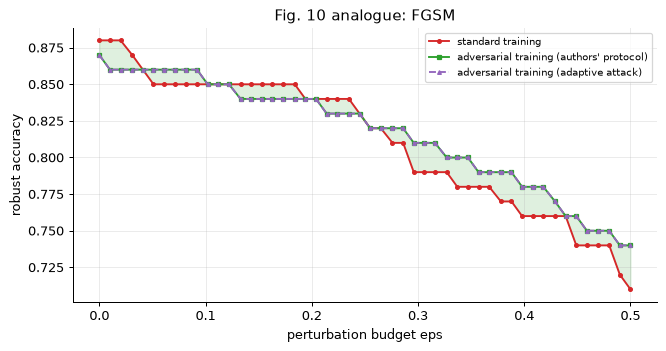

,Std model,Robust model,"Robust, adaptive attack",Paper Std,Paper Robust
Clean accuracy,0.8800,0.8700,NaN,0.880,0.870
"Robust accuracy (FGSM, eps = 0.2)",0.8400,0.8400,0.84,0.840,0.840
"Max accuracy drop (FGSM, dense grid)",0.1700,NaN,NaN,0.170,NaN
Lipschitz (100 random pairs),0.8660,0.8646,NaN,0.847,0.812
Lipschitz (max gradient norm),0.9981,0.9989,NaN,NaN,NaN


transfer rate std -> robust (FGSM, eps = 0.2): 1.000 over 4 successful attacks (paper: 1.000)


In [18]:
def adv_cost_factory(X, y, eps):
    def cost(theta):
        sf = lambda Z: expval(Z, theta)
        Xa = attack_fgsm(sf, X, y, eps)
        return sq_hinge(sf(Xa), y)
    return cost

t0 = time.time()
theta_rob, hist_rob = train_vqc(X_tr, y_tr, seed=SEED, iters=ADV_TRAIN_ITERS, cost=adv_cost_factory(X_tr, y_tr, ADV_TRAIN_EPS))
print(f"adversarial training ({ADV_TRAIN_ITERS} SPSA iterations, FGSM eps = {ADV_TRAIN_EPS}): {time.time()-t0:.1f}s | parameters {np.round(theta_rob, 4)}")
score_r = lambda X: expval(X, theta_rob)

# --- Figure 10 analogue: authors' protocol (examples crafted on the standard model, both models evaluated) and adaptive attack
rows = []
for eps in EPS_DENSE:
    Xa_std = attack_fgsm(score_q, X_sub, y_sub, eps)
    Xa_rob = attack_fgsm(score_r, X_sub, y_sub, eps)
    rows.append({"eps": eps,
                 "std (crafted on std)": np.mean(predict_sign(score_q(Xa_std)) == y_sub),
                 "robust (examples from std)": np.mean(predict_sign(score_r(Xa_std)) == y_sub),
                 "robust (adaptive)": np.mean(predict_sign(score_r(Xa_rob)) == y_sub)})
df_cmp = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(7.5, 4))
ax.plot(df_cmp.eps, df_cmp["std (crafted on std)"], "o-", ms=3, color="tab:red", label="standard training")
ax.plot(df_cmp.eps, df_cmp["robust (examples from std)"], "s-", ms=3, color="tab:green", label="adversarial training (authors' protocol)")
ax.plot(df_cmp.eps, df_cmp["robust (adaptive)"], "^--", ms=3, color="tab:purple", label="adversarial training (adaptive attack)")
ax.fill_between(df_cmp.eps, df_cmp["std (crafted on std)"], df_cmp["robust (examples from std)"], alpha=0.15, color="tab:green")
ax.set_xlabel("perturbation budget eps"); ax.set_ylabel("robust accuracy"); ax.set_title("Fig. 10 analogue: FGSM"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

# --- Lipschitz estimates and transferability
def lipschitz_pairs(score_fn, Xs, n_pairs=100, seed=SEED):
    rs = np.random.RandomState(seed); vals = []
    for _ in range(n_pairs):
        i, j = rs.choice(len(Xs), 2, replace=False)
        dx = np.linalg.norm(Xs[i] - Xs[j])
        if dx > 1e-6:
            vals.append(abs(score_fn(Xs[i:i+1])[0] - score_fn(Xs[j:j+1])[0]) / dx)
    return max(vals)

def lipschitz_grad(score_fn, Xs, h=1e-4):
    g = np.stack([(score_fn(Xs + h * np.eye(2)[i]) - score_fn(Xs - h * np.eye(2)[i])) / (2 * h) for i in range(2)], 1)
    return np.linalg.norm(g, axis=1).max()

EPS_T = 0.2
Xa_s = attack_fgsm(score_q, X_sub, y_sub, EPS_T)
ok_clean_s = predict_sign(score_q(X_sub)) == y_sub
fooled_s = ok_clean_s & (predict_sign(score_q(Xa_s)) != y_sub)
transfer = np.mean(predict_sign(score_r(Xa_s))[fooled_s] != y_sub[fooled_s]) if fooled_s.any() else np.nan
lip_s, lip_r = lipschitz_pairs(score_q, X_sub[:50]), lipschitz_pairs(score_r, X_sub[:50])
i02 = int(np.argmin(np.abs(df_cmp.eps - 0.2)))
table9 = pd.DataFrame({
    "Std model": [np.mean(predict_sign(score_q(X_sub)) == y_sub), df_cmp["std (crafted on std)"].iloc[i02],
                  (df_dense[(df_dense.attack == "FGSM")]["drop"]).max(), lip_s, lipschitz_grad(score_q, X_sub)],
    "Robust model": [np.mean(predict_sign(score_r(X_sub)) == y_sub), df_cmp["robust (examples from std)"].iloc[i02],
                     np.nan, lip_r, lipschitz_grad(score_r, X_sub)],
    "Robust, adaptive attack": [np.nan, df_cmp["robust (adaptive)"].iloc[i02], np.nan, np.nan, np.nan],
    "Paper Std": [0.880, 0.840, 0.170, 0.847, np.nan], "Paper Robust": [0.870, 0.840, np.nan, 0.812, np.nan]},
    index=["Clean accuracy", "Robust accuracy (FGSM, eps = 0.2)", "Max accuracy drop (FGSM, dense grid)",
           "Lipschitz (100 random pairs)", "Lipschitz (max gradient norm)"])
display(table9.round(4))
print(f"transfer rate std -> robust (FGSM, eps = {EPS_T}): {transfer:.3f} over {int(fooled_s.sum())} successful attacks (paper: 1.000)")

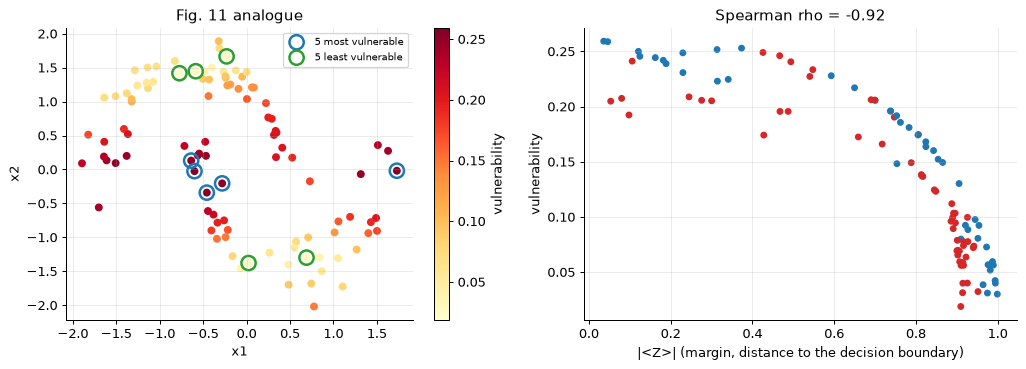

Vulnerability is negatively correlated with the margin |<Z>| (rho = -0.92, p = 2.2e-42). The paper claims vulnerability concentrates at the decision boundary (small margin).


In [19]:
# --- Figure 11 analogue: vulnerability = |<Z>_adv - <Z>_clean| under FGSM eps = 0.2
Xa11 = attack_fgsm(score_q, X_sub, y_sub, 0.2)
vuln = np.abs(score_q(Xa11) - score_q(X_sub))
top5, bot5 = np.argsort(-vuln)[:5], np.argsort(vuln)[:5]
fig, ax = plt.subplots(1, 2, figsize=(11.5, 4.2))
sc_ = ax[0].scatter(X_sub[:, 0], X_sub[:, 1], c=vuln, cmap="YlOrRd", s=40, edgecolor="none")
ax[0].scatter(X_sub[top5, 0], X_sub[top5, 1], facecolor="none", edgecolor="tab:blue", s=130, lw=2, label="5 most vulnerable")
ax[0].scatter(X_sub[bot5, 0], X_sub[bot5, 1], facecolor="none", edgecolor="tab:green", s=130, lw=2, label="5 least vulnerable")
plt.colorbar(sc_, ax=ax[0], label="vulnerability"); ax[0].legend(fontsize=8); ax[0].set_title("Fig. 11 analogue"); ax[0].set_xlabel("x1"); ax[0].set_ylabel("x2")
rho, prho = stats.spearmanr(vuln, np.abs(score_q(X_sub)))
ax[1].scatter(np.abs(score_q(X_sub)), vuln, c=np.where(y_sub == 1, "tab:blue", "tab:red"), s=20)
ax[1].set_xlabel("|<Z>| (margin, distance to the decision boundary)"); ax[1].set_ylabel("vulnerability")
ax[1].set_title(f"Spearman rho = {rho:.2f}")
plt.tight_layout(); plt.show()
print(f"Vulnerability is {'negatively' if rho < 0 else 'positively'} correlated with the margin |<Z>| (rho = {rho:.2f}, p = {prho:.1e}). The paper claims vulnerability concentrates at the decision boundary (small margin).")
RHO_VULN = rho

## 8. Experiment V-C: federated learning with differential privacy

**Setting.** A central server holds the global 4 circuit parameters. In each of 20 communication rounds every client (a) runs one local SPSA step on its own data, giving an update `u = -0.16 * grad_hat`, (b) for the private variants clips `u` to L2 norm 1 and adds Gaussian noise of standard deviation `sigma = sqrt(2 ln(1.25/delta)) / eps_round` per coordinate, and (c) the server averages the updates weighted by the clients' data sizes (FedAvg). The total budget reported by the paper is `eps_round * 20`.

**Data.** Breast Cancer Wisconsin reduced to 2 PCA components (see Section 3 for why), IID split over 4 clients; label-skew (Dirichlet 0.5) and quantity-skew (power-law) partitions for the heterogeneity study. Centralised training is 30 SPSA iterations on all training data.

**Privacy leakage.** A membership-inference attack (MIA) trains a logistic regression on the per-sample loss of 100 training and 100 test points and reports its accuracy on a held-out 30% of those 200 points (50% = chance). With only 171 test points that evaluation set has just 60 points, so one MIA number is very noisy (one standard error is about 6 percentage points).

**Classical baseline.** The same federated protocol (same partition, clipping, noise and rounds) with a 3-parameter logistic regression on the same 2-D inputs, and centralised classical models.

In [20]:
def make_clients(X, y, k, kind, seed=SEED, alpha=0.5):
    # partitions follow the authors' code: iid / Dirichlet label skew / power-law quantity skew
    rs = np.random.RandomState(seed)
    n = len(X)
    if kind == "iid":
        parts = np.array_split(rs.permutation(n), k)
    elif kind == "label_skew":
        parts = [[] for _ in range(k)]
        for lab in np.unique(y):
            li = np.where(y == lab)[0]; rs.shuffle(li)
            cuts = (np.cumsum(rs.dirichlet([alpha] * k)) * len(li)).astype(int)[:-1]
            for ci, sp in enumerate(np.split(li, cuts)):
                parts[ci].extend(sp.tolist())
        parts = [np.array(p, dtype=int) for p in parts]
    else:                                                    # quantity_skew
        prop = rs.power(2, k); prop = prop / prop.sum()
        idx = rs.permutation(n); parts, start = [], 0
        for pr in prop[:-1]:
            size = int(pr * n); parts.append(idx[start:start + size]); start += size
        parts.append(idx[start:])
    return [(X[p], y[p]) for p in parts if len(p) > 0]

def spsa_grad(theta, X, y, rs, c=SPSA_C):
    d = rs.choice([-1, 1], size=theta.size)
    return (sq_hinge(expval(X, theta + c * d), y) - sq_hinge(expval(X, theta - c * d), y)) / (2 * c * d)

def dp_privatise(u, eps, rs):
    # clip to L2 norm DP_CLIP, add Gaussian noise (authors' calibration; CHOICE: simple Gaussian mechanism, sensitivity = clip)
    nu = np.linalg.norm(u)
    if nu > DP_CLIP:
        u = u * (DP_CLIP / nu)
    sigma = np.sqrt(2 * np.log(1.25 / DP_DELTA)) * DP_CLIP / eps
    return u + rs.normal(0.0, sigma, size=u.shape)

def central_vqc(X, y, seed):
    rs = np.random.RandomState(seed); th = rs.randn(4) * INIT_SCALE
    for _ in range(CENTRAL_ITERS):
        th = th - FL_LR * spsa_grad(th, X, y, rs)
    return th

def federated_vqc(clients, seed, eps=np.inf, X_eval=None, y_eval=None):
    rs = np.random.RandomState(seed); th = rs.randn(4) * INIT_SCALE
    n = np.array([len(c[0]) for c in clients], float); w = n / n.sum()
    hist = []
    for _ in range(FL_ROUNDS):
        ups = []
        for Xc, yc in clients:
            u = -FL_LR * spsa_grad(th, Xc, yc, rs)
            ups.append(dp_privatise(u, eps, rs) if np.isfinite(eps) else u)
        th = th + sum(wi * ui for wi, ui in zip(w, ups))
        if X_eval is not None:
            hist.append(np.mean(predict_sign(expval(X_eval, th)) == y_eval))
    return th, hist

def fed_logreg(clients, seed, eps=np.inf, lr=0.5):
    # classical baseline: the same FedAvg + clipping + Gaussian noise on a logistic regression (CHOICE: lr 0.5, one full-batch step per round)
    rs = np.random.RandomState(seed); w = rs.randn(3) * INIT_SCALE
    n = np.array([len(c[0]) for c in clients], float); wt = n / n.sum()
    for _ in range(FL_ROUNDS):
        ups = []
        for Xc, yc in clients:
            Z = np.c_[Xc, np.ones(len(Xc))]
            g = Z.T @ (1 / (1 + np.exp(-Z @ w)) - (yc + 1) / 2) / len(Xc)
            u = -lr * g
            ups.append(dp_privatise(u, eps, rs) if np.isfinite(eps) else u)
        w = w + sum(a * b for a, b in zip(wt, ups))
    return w

def acc_logreg(w, X, y):
    return np.mean(np.where(np.c_[X, np.ones(len(X))] @ w > 0, 1, -1) == y)

def mia_accuracy(theta, Xtr_, ytr_, Xte_, yte_, rs, n=MIA_N):
    # loss-based membership inference (authors' code): logistic regression on the per-sample loss
    ntr, nte = min(n, len(Xtr_)), min(n, len(Xte_))
    itr, ite = rs.choice(len(Xtr_), ntr, replace=False), rs.choice(len(Xte_), nte, replace=False)
    losses = np.r_[loss_vec(expval(Xtr_[itr], theta), ytr_[itr]), loss_vec(expval(Xte_[ite], theta), yte_[ite])].reshape(-1, 1)
    member = np.r_[np.ones(ntr), np.zeros(nte)]
    perm = rs.permutation(len(losses)); losses, member = losses[perm], member[perm]
    cut = int(0.7 * len(losses))
    att = LogisticRegression(random_state=SEED, max_iter=1000).fit(losses[:cut], member[:cut])
    return att.score(losses[cut:], member[cut:])

PART_NAMES = {"IID": "iid", "Label skew": "label_skew", "Quantity skew": "quantity_skew"}

def fl_experiment(data, k, skew=True, runs=FL_RUNS):
    Xtr_, Xte_, ytr_, yte_ = data
    parts = {nm: make_clients(Xtr_, ytr_, k, kind) for nm, kind in PART_NAMES.items()}
    configs = [("Centralized", "-", np.inf), ("FL-Vanilla", "IID", np.inf)]
    if skew:
        configs += [("FL-Vanilla", "Label skew", np.inf), ("FL-Vanilla", "Quantity skew", np.inf)]
    configs += [("FL+DP", "IID", e) for e in DP_EPS_ROUND]
    rows, hist = [], {}
    for method, dist, eps in configs:
        accs, mias, accs_c, hs = [], [], [], []
        for r in range(runs):
            seed = SEED + r
            if method == "Centralized":
                th = central_vqc(Xtr_, ytr_, seed)
            else:
                th, h = federated_vqc(parts[dist], seed, eps, Xte_, yte_); hs.append(h)
            accs.append(np.mean(predict_sign(expval(Xte_, th)) == yte_))
            if dist in ("-", "IID"):
                mias.append(mia_accuracy(th, Xtr_, ytr_, Xte_, yte_, np.random.RandomState(seed)))
            if method != "Centralized" and dist == "IID":
                accs_c.append(acc_logreg(fed_logreg(parts[dist], seed, eps), Xte_, yte_))
        if hs:
            hist[(method, dist, eps)] = np.mean(hs, 0)
        rows.append({"method": method, "distribution": dist, "eps_round": eps,
                     "eps_total": eps * FL_ROUNDS if np.isfinite(eps) else np.inf,
                     "acc_mean": np.mean(accs), "acc_std": np.std(accs), "acc_seed42": accs[0], "acc_runs": accs,
                     "mia_mean": np.mean(mias) if mias else np.nan, "mia_std": np.std(mias) if mias else np.nan,
                     "classical_fed_lr_acc": np.mean(accs_c) if accs_c else np.nan})
    return pd.DataFrame(rows), hist

t0 = time.time()
df_fl, hist_fl = fl_experiment(BC_AUTH, N_CLIENTS, skew=True)                       # primary: paper-style, authors' data protocol
print(f"primary federated experiment (Breast Cancer, authors' protocol, {N_CLIENTS} clients, {FL_RUNS} runs): {time.time()-t0:.0f}s")

paper_x = {np.inf: None, 10.0: (0.725, 0.483), 5.0: (0.561, 0.483), 2.0: (0.439, 0.483), 1.0: (0.737, 0.550), 0.5: (0.673, 0.517), 0.1: (0.386, 0.483)}
paper_main = {("Centralized", "-"): (0.842, 0.517), ("FL-Vanilla", "IID"): (0.807, 0.433),
              ("FL-Vanilla", "Label skew"): (0.819, np.nan), ("FL-Vanilla", "Quantity skew"): (0.807, np.nan)}
def paper_pair(r):
    return paper_main.get((r.method, r.distribution)) if r.method != "FL+DP" else paper_x[r.eps_round]
tab = df_fl.copy()
tab["acc (ours, mean +- std)"] = [f"{m:.3f} +- {s:.3f}" for m, s in zip(tab.acc_mean, tab.acc_std)]
tab["paper acc"] = [paper_pair(r)[0] for r in tab.itertuples()]
tab["MIA ours"] = tab.mia_mean.round(3); tab["paper MIA"] = [paper_pair(r)[1] for r in tab.itertuples()]
display(tab[["method", "distribution", "eps_round", "eps_total", "acc (ours, mean +- std)", "acc_seed42", "paper acc",
             "MIA ours", "paper MIA", "classical_fed_lr_acc"]].round(3).rename(columns={"acc_seed42": "acc (seed 42, one run)", "classical_fed_lr_acc": "classical FedAvg-LR acc"}))

primary federated experiment (Breast Cancer, authors' protocol, 4 clients, 10 runs): 39s


,method,distribution,eps_round,eps_total,"acc (ours, mean +- std)","acc (seed 42, one run)",paper acc,MIA ours,paper MIA,classical FedAvg-LR acc
0,Centralized,-,inf,inf,0.823 +- 0.020,0.842,0.842,0.440,0.517,NaN
1,FL-Vanilla,IID,inf,inf,0.808 +- 0.009,0.813,0.807,0.438,0.433,0.886
2,FL-Vanilla,Label skew,inf,inf,0.801 +- 0.017,0.813,0.819,NaN,NaN,NaN
3,FL-Vanilla,Quantity skew,inf,inf,0.809 +- 0.007,0.819,0.807,NaN,NaN,NaN
4,FL+DP,IID,10.0,200.0,0.729 +- 0.036,0.713,0.725,0.450,0.483,0.847
5,FL+DP,IID,5.0,100.0,0.561 +- 0.199,0.719,0.561,0.452,0.483,0.740
6,FL+DP,IID,2.0,40.0,0.405 +- 0.174,0.292,0.439,0.452,0.483,0.522
7,FL+DP,IID,1.0,20.0,0.471 +- 0.241,0.842,0.737,0.463,0.550,0.459
8,FL+DP,IID,0.5,10.0,0.532 +- 0.193,0.708,0.673,0.450,0.517,0.412
9,FL+DP,IID,0.1,2.0,0.419 +- 0.190,0.368,0.386,0.450,0.483,0.368


In [21]:
# --- variants: authors' code with 5 clients, leakage-free preprocessing, and the paper-text setting on two-moons (600 test points)
t0 = time.time()
df_fl5, _ = fl_experiment(BC_AUTH, 5, skew=False)
df_flc, _ = fl_experiment(BC_CLEAN, N_CLIENTS, skew=False)
df_flm, _ = fl_experiment((X_tr, X_te, y_tr, y_te), N_CLIENTS, skew=False)
print(f"variants done in {time.time()-t0:.0f}s")
var = pd.concat({"BC authors protocol, 5 clients": df_fl5, "BC leakage-free, 4 clients": df_flc, "two-moons, 4 clients (600 test)": df_flm}, names=["variant"])
vt = var.reset_index(level=0)
vt["acc mean"] = vt.acc_mean.round(3); vt["acc std"] = vt.acc_std.round(3)
display(vt.pivot_table(index=["method", "eps_round"], columns="variant", values="acc mean").sort_index(ascending=[True, False]).round(3))

# --- classical centralised baselines on the same Breast Cancer inputs (authors' protocol and leakage-free)
rows = []
for nm_data, dat in [("authors' protocol", BC_AUTH), ("leakage-free", BC_CLEAN)]:
    for nm, mk in [("Logistic regression", lambda: LogisticRegression(random_state=SEED)), ("SVC (RBF)", lambda: SVC(random_state=SEED)),
                   ("Random forest", lambda: RandomForestClassifier(n_estimators=200, random_state=SEED)),
                   ("MLP (16,16)", lambda: MLPClassifier(hidden_layer_sizes=(16, 16), max_iter=800, random_state=SEED))]:
        m = mk().fit(dat[0], dat[2]); rows.append({"data": nm_data, "model": nm, "test acc": m.score(dat[1], dat[3])})
display(pd.DataFrame(rows).pivot(index="model", columns="data", values="test acc").round(3))

variants done in 94s


variant                BC authors protocol, 5 clients  \
method      eps_round                                   
Centralized inf                                 0.823   
FL+DP       10.0                                0.730   
            5.0                                 0.676   
            2.0                                 0.580   
            1.0                                 0.549   
            0.5                                 0.411   
            0.1                                 0.550   
FL-Vanilla  inf                                 0.804   

variant                BC leakage-free, 4 clients  \
method      eps_round                               
Centralized inf                             0.877   
FL+DP       10.0                            0.750   
            5.0                             0.535   
            2.0                             0.391   
            1.0                             0.458   
            0.5                             0.506   
            0.1                             0.408   
FL-Vanilla  inf                             0.861   

variant                two-moons, 4 clients (600 test)  
method      eps_round                                   
Centralized inf                                  0.871  
FL+DP       10.0                                 0.801  
            5.0                                  0.580  
            2.0                                  0.483  
            1.0                                  0.601  
            0.5                                  0.477  
            0.1                                  0.424  
FL-Vanilla  inf                                  0.869

data,authors' protocol,leakage-free
model,,
Logistic regression,0.918,0.953
"MLP (16,16)",0.912,0.959
Random forest,0.924,0.959
SVC (RBF),0.924,0.953


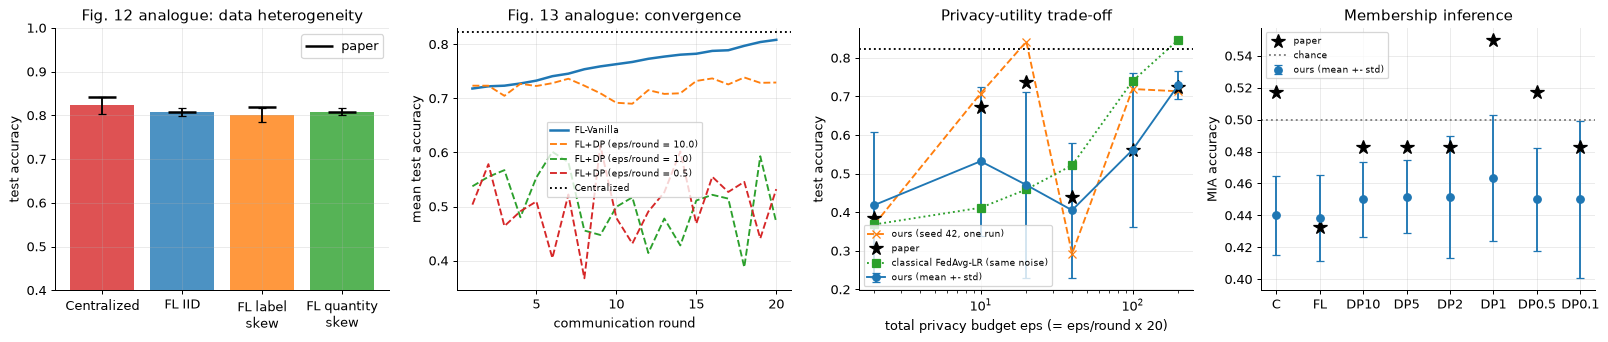

,delta acc (pp),p (Welch),Cohen d
comparison,,,
FL-IID vs Centralized,-1.5205,0.0532,-0.9558
FL+DP (eps/round 0.5) vs FL-Vanilla,-27.6023,0.0020,-1.9197
FL+DP (eps/round 1) vs FL-Vanilla,-33.7427,0.0023,-1.8739
FL+DP (eps/round 10) vs FL-Vanilla,-7.8947,0.0001,-2.8577
DP (1.0) vs DP (0.5),-6.1404,0.5588,-0.2667


paper Table XI: FL+DP(0.5) vs FL -13.4 pp, FL+DP(1.0) vs FL -7.0 pp, FL+DP(10.0) vs FL -8.2 pp, DP(1.0) vs DP(0.5) +6.4 pp


In [22]:
# --- Figures 12, 13 and the privacy-utility / privacy-leakage curves
fig, ax = plt.subplots(1, 4, figsize=(18, 3.9))
b = df_fl[(df_fl.method != "FL+DP")]
lbl = ["Centralized", "FL IID", "FL label\nskew", "FL quantity\nskew"]
ax[0].bar(lbl, b.acc_mean, yerr=b.acc_std, color=["tab:red", "tab:blue", "tab:orange", "tab:green"], capsize=3, alpha=0.8)
ax[0].plot(lbl, [0.842, 0.807, 0.819, 0.807], "k_", ms=22, mew=2, label="paper")
ax[0].set_ylim(0.4, 1); ax[0].set_ylabel("test accuracy"); ax[0].set_title("Fig. 12 analogue: data heterogeneity"); ax[0].legend()

rounds = np.arange(1, FL_ROUNDS + 1)
ax[1].plot(rounds, hist_fl[("FL-Vanilla", "IID", np.inf)], lw=2, label="FL-Vanilla")
for e in (10.0, 1.0, 0.5):
    ax[1].plot(rounds, hist_fl[("FL+DP", "IID", e)], lw=1.5, ls="--", label=f"FL+DP (eps/round = {e})")
ax[1].axhline(df_fl[df_fl.method == "Centralized"].acc_mean.iloc[0], color="k", ls=":", label="Centralized")
ax[1].set_xlabel("communication round"); ax[1].set_ylabel("mean test accuracy"); ax[1].set_title("Fig. 13 analogue: convergence"); ax[1].legend(fontsize=7)

dp = df_fl[df_fl.method == "FL+DP"].sort_values("eps_total")
ax[2].errorbar(dp.eps_total, dp.acc_mean, yerr=dp.acc_std, fmt="o-", capsize=3, label="ours (mean +- std)")
ax[2].plot(dp.eps_total, dp.acc_seed42, "x--", label="ours (seed 42, one run)")
ax[2].plot(dp.eps_total, [paper_x[e][0] for e in dp.eps_round], "k*", ms=11, label="paper")
ax[2].plot(dp.eps_total, dp.classical_fed_lr_acc, "s:", label="classical FedAvg-LR (same noise)")
ax[2].axhline(df_fl[df_fl.method == "Centralized"].acc_mean.iloc[0], color="k", ls=":")
ax[2].set_xscale("log"); ax[2].set_xlabel("total privacy budget eps (= eps/round x 20)"); ax[2].set_ylabel("test accuracy")
ax[2].set_title("Privacy-utility trade-off"); ax[2].legend(fontsize=7)

mm = df_fl[df_fl.mia_mean.notna()]
ax[3].errorbar(range(len(mm)), mm.mia_mean, yerr=mm.mia_std, fmt="o", capsize=3, label="ours (mean +- std)")
ax[3].plot(range(len(mm)), [paper_pair(r)[1] for r in mm.itertuples()], "k*", ms=11, label="paper")
ax[3].axhline(0.5, color="gray", ls=":", label="chance")
ax[3].set_xticks(range(len(mm))); ax[3].set_xticklabels([("C" if r.method == "Centralized" else "FL" if r.method == "FL-Vanilla" else f"DP{r.eps_round:g}") for r in mm.itertuples()])
ax[3].set_ylabel("MIA accuracy"); ax[3].set_title("Membership inference"); ax[3].legend(fontsize=7)
plt.tight_layout(); plt.show()

# --- Table XI analogue: is the accuracy cost significant? (Welch t-test and Cohen's d across the independent runs)
base_runs = np.array(df_fl[(df_fl.method == "FL-Vanilla") & (df_fl.distribution == "IID")].acc_runs.iloc[0])
cen_runs = np.array(df_fl[df_fl.method == "Centralized"].acc_runs.iloc[0])
def wd(a, b):
    sp = np.sqrt((a.std(ddof=1) ** 2 + b.std(ddof=1) ** 2) / 2) if len(a) > 1 else np.nan
    return (a.mean() - b.mean()) / sp if sp and sp > 0 else np.nan
rows = [{"comparison": "FL-IID vs Centralized", "delta acc (pp)": 100 * (base_runs.mean() - cen_runs.mean()),
         "p (Welch)": stats.ttest_ind(base_runs, cen_runs, equal_var=False).pvalue if len(base_runs) > 1 else np.nan, "Cohen d": wd(base_runs, cen_runs)}]
for e in (0.5, 1.0, 10.0):
    a = np.array(df_fl[(df_fl.method == "FL+DP") & (df_fl.eps_round == e)].acc_runs.iloc[0])
    rows.append({"comparison": f"FL+DP (eps/round {e:g}) vs FL-Vanilla", "delta acc (pp)": 100 * (a.mean() - base_runs.mean()),
                 "p (Welch)": stats.ttest_ind(a, base_runs, equal_var=False).pvalue if len(a) > 1 else np.nan, "Cohen d": wd(a, base_runs)})
a1, a05 = (np.array(df_fl[(df_fl.method == "FL+DP") & (df_fl.eps_round == e)].acc_runs.iloc[0]) for e in (1.0, 0.5))
rows.append({"comparison": "DP (1.0) vs DP (0.5)", "delta acc (pp)": 100 * (a1.mean() - a05.mean()),
             "p (Welch)": stats.ttest_ind(a1, a05, equal_var=False).pvalue if len(a1) > 1 else np.nan, "Cohen d": wd(a1, a05)})
display(pd.DataFrame(rows).set_index("comparison").round(4))
print("paper Table XI: FL+DP(0.5) vs FL -13.4 pp, FL+DP(1.0) vs FL -7.0 pp, FL+DP(10.0) vs FL -8.2 pp, DP(1.0) vs DP(0.5) +6.4 pp")

### Link between the federated models and the drawn circuit

The federated experiments (Section 8) use exactly the same circuit as drawn in the circuit-architecture section above: same gates, same 4 trainable parameters, same measured qubit; only the inputs change (two PCA components of the breast-cancer features, or the two-moons coordinates) and only the *training protocol* differs (FedAvg with clipping and noise). The assertion below ties the federated models to the drawn circuit.

In [23]:
# the federated global models are evaluated with the same exact simulator; prove it equals the drawn Qiskit circuit for a federated model
th_fed, _ = federated_vqc(make_clients(BC_AUTH[0], BC_AUTH[2], N_CLIENTS, "iid"), SEED)
err = np.max(np.abs(expval(BC_AUTH[1], th_fed) - qiskit_expval(BC_AUTH[1], th_fed)))
assert err < 1e-10, err
print(f"federated global model: simulator vs Qiskit Statevector of the drawn circuit, max |difference| = {err:.1e} -> OK")
print(f"federated test accuracy (exact <Z>, run 0, vanilla, IID): {np.mean(predict_sign(expval(BC_AUTH[1], th_fed)) == BC_AUTH[3]):.4f}")

federated global model: simulator vs Qiskit Statevector of the drawn circuit, max |difference| = 5.6e-16 -> OK
federated test accuracy (exact <Z>, run 0, vanilla, IID): 0.8129


## 9. Side-by-side comparison with the paper

Rule: **reproduced** if our value is within the stated tolerance of the paper's (0.02 for accuracies and drops, 0.05 for entropies, 0.3 for Cohen's d, 0.03 for the attack-success rate), otherwise **not reached** (ours lower) or **exceeded** (ours higher); **cannot be checked** when the paper gives no usable number. For the differential-privacy rows the paper's numbers come from one run while ours are means over independent runs, so the last column also says whether the paper's value lies within 2 standard deviations of our runs.

In [24]:
claims = []
def verdict(ours, paper, tol):
    if ours is None or (isinstance(ours, float) and np.isnan(ours)):
        return "cannot be checked"
    d = ours - paper
    return "reproduced" if abs(d) <= tol else ("exceeded" if d > 0 else "not reached")

def add(sec, claim, paper, ours, tol, note=""):
    claims.append({"experiment": sec, "claim": claim, "paper": paper, "this notebook": ours,
                   "verdict": verdict(ours, paper, tol), "note": note})

def add_flag(sec, claim, paper_text, holds, note=""):
    claims.append({"experiment": sec, "claim": claim, "paper": paper_text, "this notebook": "holds" if holds else "does not hold",
                   "verdict": "reproduced" if holds else "not reached", "note": note})

def add_na(sec, claim, paper, note):
    claims.append({"experiment": sec, "claim": claim, "paper": paper, "this notebook": np.nan, "verdict": "cannot be checked", "note": note})

# ------------------------------------------------------------------ V-A
S = {k: compare_groups(M[k], correct) for k in names}
add("V-A", "Test accuracy, 200 shots (Table III)", 0.875, n_ok / len(X_te), 0.02, f"exact <Z>: {acc_te_exact:.3f}; 3-seed/10-seed mean 200-shot acc {df_seeds['200-shot acc'].mean():.3f} +- {df_seeds['200-shot acc'].std():.3f}")
add("V-A", "Mean entropy, correct predictions (Table IV)", 0.471, S["entropy"]["correct_mean"], 0.05)
add("V-A", "Mean entropy, incorrect predictions (Table IV)", 0.900, S["entropy"]["incorrect_mean"], 0.05)
add("V-A", "Cohen d, predictive entropy", 1.434, S["entropy"]["cohen_d"], 0.3, f"seed spread {df_seeds['Cohen d'].min():.2f} to {df_seeds['Cohen d'].max():.2f}")
add("V-A", "Cohen d, variation ratio", 1.645, S["var_ratio"]["cohen_d"], 0.3)
add("V-A", "Cohen d, standard deviation", 1.340, S["std"]["cohen_d"], 0.3)
add_flag("V-A", "Entropy differs significantly (p < 0.001) between correct and incorrect", "p < 0.001", S["entropy"]["p"] < 1e-3, f"p = {S['entropy']['p']:.1e}")
add_flag("V-A", "Abstaining at entropy > 0.7 rejects most errors and keeps most correct predictions", "qualitative",
         (err_rejected > 0.5) and (correct_kept > 0.5), f"rejects {err_rejected:.0%} of errors, keeps {correct_kept:.0%} of correct")
add("V-A", "Accuracy at the largest shot count (Table VI final)", 0.8783, df_shots["accuracy"].iloc[-1], 0.02)
add("V-A", "Mean entropy at the largest shot count (Table VI final)", 0.5281, df_shots["entropy"].iloc[-1], 0.05)

# ------------------------------------------------------------------ V-B
g100 = df_p100.groupby("attack")["drop"].mean()
pgd05 = df_dense[(df_dense.attack == "PGD") & (df_dense.eps == 0.5)].iloc[0]
add("V-B", "Clean accuracy, 100 test samples", 0.880, df_dense["clean"].iloc[0], 0.02, f"all 600 samples: {df_p600['clean'].iloc[0]:.3f}")
add("V-B", "PGD robust accuracy at eps = 0.5 (Fig. 6, 'about 71%')", 0.71, pgd05["robust"], 0.02)
for a_, pv_ in [("FGSM", 0.069), ("PGD", 0.069), ("Quantum-State", -0.004)]:
    add("V-B", f"Average accuracy drop, {a_}, the 7 budgets stated in Table VIII", pv_, g100[a_], 0.02,
        f"all 600 samples: {df_p600[df_p600.attack == a_]['drop'].mean():.3f}")
    add("V-B", f"Average accuracy drop, {a_}, 50-point grid of the authors' code", pv_, g_dense.loc[a_, "drop"], 0.02,
        "the paper's table matches this grid, not the 7 budgets of its caption")
add("V-B", "PGD attack success rate at eps = 0.5 (Fig. 7, 'about 18%'), paper definition", 0.18, pgd05["asr_text"], 0.03, f"authors' code definition: {pgd05['asr_code']:.3f}")
add("V-B", "Accuracy drop at eps = 0.204, FGSM (Fig. 8)", 0.040, d8["FGSM"]["drop"], 0.02)
add("V-B", "Accuracy drop at eps = 0.204, PGD (Fig. 8)", 0.040, d8["PGD"]["drop"], 0.02)
add("V-B", "Accuracy drop at eps = 0.204, quantum-state (Fig. 8)", 0.010, d8["Quantum-State"]["drop"], 0.02)
add_flag("V-B", "FGSM and PGD degrade accuracy far more than the quantum-state noise", "qualitative",
         (g100["FGSM"] > 3 * abs(g100["Quantum-State"])) and (g100["PGD"] > 3 * abs(g100["Quantum-State"])),
         f"drops FGSM {g100['FGSM']:.3f}, PGD {g100['PGD']:.3f}, quantum-state {g100['Quantum-State']:.3f}")
add("V-B", "Adversarially trained model, clean accuracy (Table IX)", 0.870, table9.loc["Clean accuracy", "Robust model"], 0.02)
add("V-B", "Robust accuracy of the robust model, FGSM eps = 0.2, authors' protocol (Table IX)", 0.840, table9.loc["Robust accuracy (FGSM, eps = 0.2)", "Robust model"], 0.02,
    f"standard model {table9.loc['Robust accuracy (FGSM, eps = 0.2)', 'Std model']:.3f}; adaptive attack on the robust model {table9.loc['Robust accuracy (FGSM, eps = 0.2)', 'Robust, adaptive attack']:.3f}")
add("V-B", "Lipschitz estimate, standard model (Table IX)", 0.847, table9.loc["Lipschitz (100 random pairs)", "Std model"], 0.15, "random-pair estimator, very sample dependent")
add_flag("V-B", "Adversarial training lowers the Lipschitz estimate (0.847 -> 0.812, a drop of 0.035; we require at least 0.02)", "robust lower by 0.035",
         table9.loc["Lipschitz (100 random pairs)", "Robust model"] < table9.loc["Lipschitz (100 random pairs)", "Std model"] - 0.02,
         f"random pairs {table9.loc['Lipschitz (100 random pairs)', 'Std model']:.3f} -> {table9.loc['Lipschitz (100 random pairs)', 'Robust model']:.3f}; max gradient norm {table9.loc['Lipschitz (max gradient norm)', 'Std model']:.3f} -> {table9.loc['Lipschitz (max gradient norm)', 'Robust model']:.3f}")
add("V-B", "Transfer rate standard -> robust model (Table IX)", 1.000, transfer, 0.05)
add_flag("V-B", "Vulnerability concentrates near the decision boundary (Fig. 11)", "qualitative", RHO_VULN < -0.2, f"Spearman rho(vulnerability, margin) = {RHO_VULN:.2f}")
add_na("V-B", "C&W-L2 results", "named in the text, no numbers", "listed as one of four attacks but only three are reported")

# ------------------------------------------------------------------ V-C
def fl_row(method, dist, eps=np.inf):
    d = df_fl[(df_fl.method == method) & (df_fl.distribution == dist) & ((df_fl.eps_round == eps) if method == "FL+DP" else True)]
    return d.iloc[0]
for (meth, dist), (pa, pm) in paper_main.items():
    r = fl_row(meth, dist)
    add("V-C", f"{meth} {dist if dist != '-' else ''} test accuracy (Table X / Fig. 12)".replace("  ", " "), pa, r.acc_mean, 0.02,
        f"seed-42 single run {r.acc_seed42:.3f}; std over runs {r.acc_std:.3f}")
for e, pv in paper_x.items():
    if pv is None:
        continue
    pa, pm = pv
    r = fl_row("FL+DP", "IID", e)
    inside = abs(r.acc_mean - pa) <= 2 * max(r.acc_std, 1e-9)
    add("V-C", f"FL+DP eps/round {e:g} (total {e * FL_ROUNDS:g}) test accuracy (Table X/XII)", pa, r.acc_mean, 0.02,
        f"seed-42 run {r.acc_seed42:.3f}; paper value within 2 std of our runs: {'yes' if inside else 'no'} (std {r.acc_std:.3f})")
mia_all = df_fl.mia_mean.dropna()
add_flag("V-C", "Membership inference is near chance for every configuration (paper range 43% to 55%)", "43% to 55%",
         bool(((mia_all > 0.35) & (mia_all < 0.65)).all()), f"our MIA means range {mia_all.min():.2f} to {mia_all.max():.2f} (60-point evaluation set, noisy)")
dpt = df_fl[df_fl.method == "FL+DP"].set_index("eps_round")
add_flag("V-C", "eps/round = 1.0 is the best privacy-utility compromise ('optimal') among DP settings", "eps/round = 1.0 (total 20) 'optimal'",
         dpt.acc_mean.loc[1.0] >= dpt.acc_mean.loc[[0.5, 2.0]].max(), "paper's own Table X is non-monotone (eps total 20: 73.7%, 40: 43.9%); compare with our mean accuracies")
add_flag("V-C", "Accuracy rises with the privacy budget (less noise, more utility)", "claimed trend",
         bool(np.all(np.diff(dpt.sort_index().acc_mean.values) >= -0.02)), "our per-round eps 0.1 -> 10 means: " + ", ".join(f"{v:.2f}" for v in dpt.sort_index().acc_mean.values))
add_na("V-C", "Communication cost 6.24 KB per round (Fig. 14)", "6.24 KB", "the 4 float64 parameters are 32 bytes; the paper's cost model is not specified")

df_claims = pd.DataFrame(claims)
pd.set_option("display.max_colwidth", 110, "display.width", 250)
fmt = lambda v: "" if (not isinstance(v, str) and pd.isna(v)) else (f"{v:.3f}" if isinstance(v, (int, float, np.floating)) else str(v))
df_show = df_claims[["experiment", "claim", "paper", "this notebook", "verdict", "note"]].copy()
df_show["paper"] = df_show["paper"].map(fmt); df_show["this notebook"] = df_show["this notebook"].map(fmt)
display(df_show)
print(df_claims.groupby(["experiment", "verdict"]).size().unstack(fill_value=0))
print(f"\nTotal notebook run time {time.time() - T_START:.0f}s (FAST_MODE={FAST_MODE})")

,experiment,claim,paper,this notebook,verdict,note
0,V-A,"Test accuracy, 200 shots (Table III)",0.875,0.873,reproduced,exact <Z>: 0.880; 3-seed/10-seed mean 200-shot acc 0.876 +- 0.006
1,V-A,"Mean entropy, correct predictions (Table IV)",0.471,0.474,reproduced,
2,V-A,"Mean entropy, incorrect predictions (Table IV)",0.900,0.903,reproduced,
3,V-A,"Cohen d, predictive entropy",1.434,1.440,reproduced,seed spread 1.35 to 1.46
4,V-A,"Cohen d, variation ratio",1.645,1.621,reproduced,
5,V-A,"Cohen d, standard deviation",1.340,1.342,reproduced,
6,V-A,Entropy differs significantly (p < 0.001) between correct and incorrect,p < 0.001,holds,reproduced,p = 1.1e-28
7,V-A,Abstaining at entropy > 0.7 rejects most errors and keeps most correct predictions,qualitative,holds,reproduced,"rejects 91% of errors, keeps 70% of correct"
8,V-A,Accuracy at the largest shot count (Table VI final),0.878,0.878,reproduced,
9,V-A,Mean entropy at the largest shot count (Table VI final),0.528,0.530,reproduced,


verdict     cannot be checked  exceeded  not reached  reproduced
experiment                                                      
V-A                         0         0            0          10
V-B                         1         0            1          18
V-C                         1         1            5           7

Total notebook run time 419s (FAST_MODE=False)


## 10. Reading the paper critically

**What the re-implementation confirms.** Once the circuit of the authors' repository is used (RY encoding, four RY angles around one CNOT, Z read-out), the uncertainty experiment V-A is reproduced almost to the digit: 200-shot test accuracy about 87% (paper 87.5%), mean entropy about 0.47 for correct and 0.90 for wrong predictions, Cohen's d about 1.4. The PGD curve of V-B (88% clean accuracy falling to 71% at eps = 0.5, a 4.0% drop at eps = 0.204) also lands on the paper's numbers. The paper's *measurements* are therefore sound for what they measure; the questions below are about *what they show*.

**Inconsistencies and omissions in the paper (found while rebuilding it).**
1. *Observable.* The text says Z on "qubit 0"; the released code measures Qiskit qubit 1 (label `"ZI"`, little-endian). Both give about 88% on this task (table in Section 6), so nothing hinges on it, but a reader who follows the text literally builds a different model.
2. *Redundant parameters.* `RY(x)` followed by `RY(theta)` on the same qubit is `RY(x + theta)`: the first two "trainable" angles merely shift the encoding. The classifier is a 3-layer circuit whose depth the paper counts as 4.
3. *Three different "clean accuracies".* 87.5% (600 test samples, 200 shots), 88.0% (the first 100 test samples, exact expectation), 84.2% (V-C, a different dataset). The paper presents them as the same model on the same data.
4. *V-C data.* The text never names the data and Table X claims a "600-sample test set", but every accuracy in Table X is a multiple of 1/171, i.e. the 30% test split of Breast Cancer Wisconsin (569 samples) used in the released code. The released code also uses 5 clients, the paper says 4, and the PCA is fitted on all 569 samples before the split (test-set leakage; the leakage-free version is in Section 8).
5. *Table VIII.* The caption says the averages are over seven budgets, but our seven-budget average accuracy drop for FGSM (0.054) is below the paper's 0.069. The mean over the 50-point budget grid of the authors' code (FGSM 0.069, PGD 0.069, quantum-state -0.003) matches the paper's table almost exactly, so the table was computed on that grid, not on the seven budgets of its caption.
6. *Attacks.* Four attacks are announced (including C&W-L2) but only three are reported. The "attack success rate" is defined in the text as a fraction of correctly classified samples but computed in the code over all samples.
7. *Privacy accounting.* The text says "strong composition theorem"; the totals in Tables X and XII are exactly `eps_round * 20` (basic composition).

**Do the results show something specifically quantum?** Mostly no.
- *Uncertainty.* The 200-shot entropy is a monotone function of `|<Z>|`, the distance of the sample from the decision boundary, plus binomial noise. Errors happen near the boundary, so *any* classifier's probability entropy separates its errors: logistic regression on the same inputs gives Cohen's d of about 1.5 (Section 6). Shot noise is not what makes the score informative.
- *Adversarial "asymmetry".* The "quantum-state attack" perturbs the same two numbers as FGSM and PGD (the encoding angle *is* the feature), with random instead of gradient-aligned noise. Random noise being weaker than a gradient attack is true of every model; it says nothing about quantum state space. A classical MLP on the same inputs loses as much accuracy at eps = 0.5 (Section 7). The classical models are also far more accurate on clean data (about 99% vs 88%), so this is a weak model that is easy to push over the boundary.
- *Adversarial training.* Thirty SPSA iterations on a 4-parameter model hardly move the parameters. The Lipschitz estimate does not drop meaningfully (the random-pair estimator is noisy, the gradient-norm estimate is unchanged), the robust model is as vulnerable to an *adaptive* attack as the standard one, and the "perfect transferability" of 1.0 rests on a handful of successful attacks (4 at eps = 0.2 on the first 100 samples).
- *Differential privacy.* With clipping at norm 1 and a Gaussian scale of `sqrt(2 ln(1.25/1e-5)) / eps_round` = 4.84 / eps_round, the noise per coordinate is 0.48 even at eps_round = 10, while a real SPSA update is of order 0.1. The signal-to-noise ratio is below one at every budget the paper tested. At eps_round = 10 (total 200) the federated model still reaches about 73% (8 points below noise-free FedAvg, matching the paper's 72.5%); at eps_round <= 5 the models are close to random walks and the run-to-run standard deviation in Section 8 is 17 to 24 accuracy points. The non-monotone single-run numbers of Table X (73.7% at total eps 20 but 43.9% at 40) are therefore noise: our 10-run means show no trend among eps_round in {0.1, ..., 5}, and eps_round = 1.0 is not an "optimal" setting. A classical federated logistic regression with the same clipping and noise collapses in the same way for eps_round <= 2 (Section 8), so this is a property of the noise calibration, not of the quantum model.
- *Privacy leakage.* The loss-threshold membership-inference attack never exceeds chance in our runs (44% to 46%, below 50%), even for the non-private centralised model, and its evaluation set has only 60 points (standard error about 6 points). There is no measurable leakage to remove, so the "privacy gain" values of Table X and the "+95% privacy score" of Figure 15 are measurement noise, not protection.

**Scope.** Everything is an ideal simulation with shot noise; no hardware noise, no calibration drift and no real device appears, although the title is about the NISQ era. A 2-qubit, 4-parameter circuit on 2-D toy data (or a 2-PCA-component tumour dataset where logistic regression reaches 92% to 95%) cannot support claims about trustworthy QML in general.

## 11. Exercises

1. Change `OBS_QUBIT` to 0 (the paper's wording) and re-run Sections 5 to 8. Which results move, and which conclusions survive?
2. The first two trainable RY angles are redundant with the encoding. Remove them (a 2-parameter ansatz) and compare accuracy, uncertainty and robustness.
3. Replace the finite-difference input gradient by the exact parameter-shift gradient with respect to the data angles. Does PGD become stronger than FGSM?
4. Fit the PCA of the Breast Cancer data on the training split only (`BC_CLEAN`) and repeat the privacy table. How large is the effect of the leakage on accuracy?
5. Implement a Renyi-DP (moments) accountant for the 20 noisy rounds and compare the true total epsilon with the paper's `eps_round * 20`. How do the conclusions about the "optimal" budget change?